In [1]:
import argparse
import glob
import importlib.util
import os
from pathlib import Path
import re
import warnings

import gsd.hoomd
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers the 3d projection)

import freud
import ruptures as rpt
from scipy.ndimage import gaussian_filter, uniform_filter1d
from tqdm import tqdm

## Phase diagrams

In [2]:
def collect_volume_fractions(folder, base_dir=".", use_blob=False, min_detected_frames=3, verbose=True,
                            use_projected_values=False, skip_marker="SKIP"):
    """
    Gather the dense and dilute volume fractions of one folder of trajectories.

    "Slab" in the folder name -> the 1D files, {traj}_density_summary.csv, whose
    first row is the species of interest.  Otherwise the 3D droplet files,
    {traj}_type_*_density3d_summary.csv, one per species, of which the lowest
    typeid is taken.  Searched recursively, so one sub-folder per trajectory is
    fine.

    For droplet runs with polymer_present, the dense value is taken from
    dense_vf_cuboid_pol_corrected instead of high_vf_mean, so the polymer's
    excluded volume is accounted for.

    Returns one row per trajectory: kT, dense/dilute values with their stds,
    the trajectory name, the species, and which file it came from.
    """
    folder_path = Path(base_dir) / folder
    if not folder_path.is_dir():
        raise FileNotFoundError(f"No such folder: {folder_path}")

    is_slab = "slab" in str(folder).lower()
    pattern = "*_density_summary.csv" if is_slab else "*_density3d_summary.csv"

    rows = []
    for csv_path in sorted(folder_path.rglob(pattern)):
        if skip_marker and skip_marker in str(csv_path.relative_to(folder_path)):
            continue
        table = pd.read_csv(csv_path)
        if table.empty:
            continue

        # First species: the first row for a slab file, the lowest typeid for
        # the 3D files, which are written one per species.
        if "typeid" in table.columns:
            row = table.sort_values("typeid").iloc[0]
        else:
            row = table.iloc[0]

        # A trajectory where the condensate was never detected has fallen back
        # to averaging every frame, so its numbers describe no particular phase.
        n_detected = row.get("n_frames_detected", np.nan)
        if np.isfinite(n_detected) and n_detected < min_detected_frames:
            if verbose:
                n_total = row.get("n_frames_analysed", row.get("frames_used", "?"))
                print(f"skipped (detected in {int(n_detected)}/{n_total} frames): {csv_path.name}")
            continue

        dense = row.get("high_vf_mean", np.nan)
        dense_std = row.get("high_vf_std", np.nan)
        dilute = row.get("low_vf_mean", np.nan)
        dilute_std = row.get("low_vf_std", np.nan)
        polymer = bool(row.get("polymer_present", False))

        if not is_slab and polymer:
            corrected = row.get("dense_vf_cuboid_pol_corrected", np.nan)
            if np.isfinite(corrected):
                dense = corrected
                dense_std = row.get("dense_vf_cuboid_pol_corrected_std", dense_std)      
                
        if not is_slab and use_blob:
            dense = row.get("high_vf_blob", np.nan)
            dense_std = row.get("high_vf_blob_std", np.nan)
        if not is_slab and use_projected_values:
            dense = row.get("projected_dense_vf", np.nan)
            dense_std = row.get("projected_dense_vf_std", np.nan)
            dilute = row.get("projected_dilute_vf", np.nan)
            dilute_std = row.get("projected_dilute_vf_std", np.nan)
        
        rows.append({
            "kT": row.get("kT_kJ_per_mol", np.nan),
            "dense_vf": dense,
            "dense_vf_std": dense_std,
            "dilute_vf": dilute,
            "dilute_vf_std": dilute_std,
            "trajname": row.get("trajname", csv_path.stem),
            "typeid": row.get("typeid", np.nan),
            "type_name": row.get("type_name", ""),
            "geometry": "slab" if is_slab else "droplet",
            "polymer_present": polymer,
            "n_frames_detected": row.get("n_frames_detected", np.nan),
            "source": str(csv_path),
        })
        # print(f"For temp {rows[-1]["kT"]} dilute v_f is: {dilute}")
        print(f"For temp {rows[-1]["kT"]} dense v_f is: {dense}")

    if not rows:
        raise FileNotFoundError(f"No {pattern} files under {folder_path}")

    return pd.DataFrame(rows).sort_values("kT").reset_index(drop=True)


def plot_volume_fractions(
    folders,
    base_dir=".",
    labels=None,
    binodal=True,
    phi_lim=None,
    log_phi=False,
    ax=None,
    figsize=(7.0, 5.0),
    colors=None,
    title=None,
    use_blob=False,
    use_projected_values=False,
    min_detected_frames=4
):
    """
    Dense and dilute volume fractions against temperature, for 1-3 folders.

    Filled circles and a solid line are the dense branch, open squares and a
    dashed line the dilute branch; one color per folder.  binodal=True swaps
    the axes to the usual coexistence-curve orientation, phi on x and kT on y.
    log_phi puts the volume-fraction axis on a log scale, which is often the
    only way to see both branches at once.

    Returns (fig, ax, data), where data is the concatenated table so the
    numbers behind the figure stay available.
    """
    if isinstance(folders, (str, Path)):
        folders = [folders]
    folders = list(folders)
    if labels is None:
        labels = [Path(f).name for f in folders]

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    if colors is None:
        colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

    collected = []
    legend_handles = []
    for i, (folder, label) in enumerate(zip(folders, labels)):
        data = collect_volume_fractions(folder, base_dir=base_dir, use_blob=use_blob,
                                        use_projected_values=use_projected_values,
                                        min_detected_frames=min_detected_frames)
        data["folder"] = str(folder)
        data["label"] = label
        collected.append(data)

        color = colors[i % len(colors)]
        legend_handles.append(Line2D([0], [0], color=color, linewidth=2.4, label=label))
        for column, std_column, marker, fillstyle, style, branch in (
            ("dense_vf", "dense_vf_std", "o", "full", "--", "dense"),
            ("dilute_vf", "dilute_vf_std", "o", "none", "--", "dilute"),
        ):
            good = data[np.isfinite(data[column]) & np.isfinite(data["kT"])]
            if good.empty:
                continue
            phi = good[column].to_numpy()
            err = good[std_column].to_numpy()
            kT = good["kT"].to_numpy()

            x, y = (phi, kT) if binodal else (kT, phi)
            xerr, yerr = (err, None) if binodal else (None, err)

            ax.errorbar(
                x, y, # xerr=xerr, yerr=yerr,
                marker=marker, fillstyle=fillstyle, linestyle=style,
                color=color, markersize=7, markeredgewidth=1.5,
                capsize=3, linewidth=2.4,
                label="_nolegend_",
            )

    phi_label = r"Volume fraction $\phi$"
    kT_label = r"Effective $k_BT^*$"
    if binodal:
        ax.set_xlabel(phi_label)
        ax.set_ylabel(kT_label)
        if log_phi:
            ax.set_xscale("log")
    else:
        ax.set_xlabel(kT_label)
        ax.set_ylabel(phi_label)
        if log_phi:
            ax.set_yscale("log")

    if phi_lim is not None:
        if binodal:
            ax.set_xlim(*phi_lim)
        else:
            ax.set_ylim(*phi_lim)
            
    ax.grid(alpha=0.3)
    ax.legend(handles=legend_handles, fontsize=9)
    if title:
        ax.set_title(title)
    fig.tight_layout()
    return fig, ax, pd.concat(collected, ignore_index=True)

In [3]:
### Fitting to the 2 equations code

CRITICAL_EXPONENT_POWER = 3.06     # 1/beta, the power the density gap is raised to
np.random.seed(42)

def fit_critical_point(
    data,
    power=CRITICAL_EXPONENT_POWER,
    use_errors=False,
    method="linear",
    n_last=None,
):
    """
    Critical temperature and critical volume fraction from a coexistence curve.

    Fits the two standard relations

        (phi_l - phi_v)**power = d  * (1 - T / Tc)          (order parameter)
        (phi_l + phi_v) / 2     = phi_c + s * (Tc - T)      (rectilinear diameter)

    Both are linear in T, so with method="linear" they are solved in two steps:
    the first gives Tc = -intercept / slope and d = intercept, and the second,
    evaluated at that Tc, gives s = -slope and phi_c = intercept - s * Tc.
    method="joint" then refines all four parameters at once with least squares,
    seeded from the linear result, which distributes the residuals of the two
    relations instead of letting the first dictate Tc alone.

    data: a frame with kT, dense_vf and dilute_vf (what collect_volume_fractions
    returns).  use_errors=True weights the fits by the propagated dense_vf_std
    and dilute_vf_std, and falls back to unweighted where those are missing.

    Returns a dict with Tc, phi_c, d, s, their standard errors where available,
    the number of points used and the temperature range they cover.
    """
    table = pd.DataFrame(data).copy()
    for column in ("kT", "dense_vf", "dilute_vf"):
        if column not in table.columns:
            raise KeyError(f"data needs a {column!r} column")

    table = table[np.isfinite(table["kT"])
                  & np.isfinite(table["dense_vf"])
                  & np.isfinite(table["dilute_vf"])]
    table = table.sort_values("kT")
    
    # Keep only the n_last highest temperatures: the scaling relations hold
    # near Tc, and points deep in the two-phase region bias the extrapolation.
    if n_last is not None:
        table = table.tail(int(n_last))

    T = table["kT"].to_numpy(dtype=float)
    phi_l = table["dense_vf"].to_numpy(dtype=float)
    phi_v = table["dilute_vf"].to_numpy(dtype=float)

    # if T.size < 3:
    #     raise ValueError(f"need at least 3 temperatures to fit, got {T.size}")

    gap = phi_l - phi_v
    if np.any(gap <= 0):
        raise ValueError("dense_vf must exceed dilute_vf at every temperature")

    y_gap = gap ** power
    y_mid = 0.5 * (phi_l + phi_v)

    # --- optional weights, propagated from the per-point stds ---------------
    w_gap = w_mid = None
    if use_errors and {"dense_vf_std", "dilute_vf_std"} <= set(table.columns):
        sl = table["dense_vf_std"].to_numpy(dtype=float)
        sv = table["dilute_vf_std"].to_numpy(dtype=float)
        sigma_gap = np.sqrt(np.nan_to_num(sl) ** 2 + np.nan_to_num(sv) ** 2)
        if np.all(sigma_gap > 0):
            # d(gap**p) = p * gap**(p-1) * d(gap)
            w_gap = 1.0 / (power * gap ** (power - 1.0) * sigma_gap)
            w_mid = 1.0 / (0.5 * sigma_gap)

    def _linear_fit(x, y, weights):
        """Least squares y = a*x + b, returning a, b and their standard errors."""
        coeffs, cov = np.polyfit(x, y, 1, w=weights, cov=True)
        a, b = coeffs
        err = np.sqrt(np.diag(cov))
        return float(a), float(b), float(err[0]), float(err[1]), cov

    # --- step 1: the order parameter gives Tc and d --------------------------
    a1, b1, a1_err, b1_err, cov1 = _linear_fit(T, y_gap, w_gap)
    if a1 >= 0:
        raise ValueError(
            "the density gap grows with temperature; these points do not "
            "approach a critical point"
        )
    Tc = -b1 / a1
    d = b1
    # Tc = -b/a, so propagate both terms including their covariance
    dTc_da, dTc_db = b1 / a1 ** 2, -1.0 / a1
    Tc_err = float(np.sqrt(
        dTc_da ** 2 * cov1[0, 0] + dTc_db ** 2 * cov1[1, 1]
        + 2.0 * dTc_da * dTc_db * cov1[0, 1]
    ))

    # --- step 2: the rectilinear diameter gives s and phi_c ------------------
    a2, b2, a2_err, b2_err, cov2 = _linear_fit(T, y_mid, w_mid)
    s = -a2
    phi_c = b2 - s * Tc
    phi_c_err = float(np.sqrt(
        cov2[1, 1] + (Tc * a2_err) ** 2 + (s * Tc_err) ** 2
    ))

    result = {
        "Tc": float(Tc), "Tc_err": Tc_err,
        "phi_c": float(phi_c), "phi_c_err": phi_c_err,
        "d": float(d), "d_err": float(b1_err),
        "s": float(s), "s_err": float(a2_err),
        "power": float(power),
        "n_points": int(T.size),
        "T_min": float(T.min()), "T_max": float(T.max()),
        "method": "linear",
        "weighted": w_gap is not None,
    }

    if method == "joint":
        from scipy.optimize import least_squares
        print("USED JOINT METHOD.")

        def residuals(p):
            Tc_, d_, phi_c_, s_ = p
            r1 = y_gap - d_ * (1.0 - T / Tc_)
            r2 = y_mid - (phi_c_ + s_ * (Tc_ - T))
            # scale each block by its own spread so neither dominates
            n1 = np.std(y_gap) or 1.0
            n2 = np.std(y_mid) or 1.0
            return np.concatenate([r1 / n1, r2 / n2])

        fit = least_squares(residuals, [Tc, d, phi_c, s], method="lm")
        Tc_j, d_j, phi_c_j, s_j = fit.x
        result.update({
            "Tc": float(Tc_j), "phi_c": float(phi_c_j),
            "d": float(d_j), "s": float(s_j),
            "method": "joint",
            "Tc_linear": float(Tc), "phi_c_linear": float(phi_c),
        })
        # standard errors from the Jacobian, scaled by the residual variance
        dof = max(1, 2 * T.size - 4)
        try:
            cov = np.linalg.inv(fit.jac.T @ fit.jac) * (2.0 * fit.cost / dof)
            err = np.sqrt(np.diag(cov))
            result.update({"Tc_err": float(err[0]), "d_err": float(err[1]),
                           "phi_c_err": float(err[2]), "s_err": float(err[3])})
        except np.linalg.LinAlgError:
            pass

    return result


def binodal_curve(fit, n_points=200, T_min=None):
    """
    The fitted coexistence curve, for drawing on a binodal plot.

    Returns (phi_dense, phi_dilute, T) evaluated from T_min (default: a little
    below the lowest fitted temperature) up to Tc.
    """
    Tc, d, phi_c, s = fit["Tc"], fit["d"], fit["phi_c"], fit["s"]
    power = fit.get("power", CRITICAL_EXPONENT_POWER)

    if T_min is None:
        T_min = fit["T_min"] - 0.05 * (Tc - fit["T_min"])
    T = np.linspace(T_min, Tc, n_points)

    gap = np.maximum(d * (1.0 - T / Tc), 0.0) ** (1.0 / power)
    mid = phi_c + s * (Tc - T)
    return mid + 0.5 * gap, mid - 0.5 * gap, T


def plot_binodal_fit(ax, fit, color="black", label=None, show_diameter=False,
                     show_critical_point=True):
    """Draw a fitted curve, its rectilinear diameter and the critical point."""
    phi_dense, phi_dilute, T = binodal_curve(fit)
    ax.plot(phi_dense, T, color=color, lw=1.2, alpha=0.9, ls="--"
            #label=label or f"fit: Tc={fit['Tc']:.3f}, phi_c={fit['phi_c']:.3f}"
           )
    ax.plot(phi_dilute, T, color=color, lw=1.2, alpha=0.9, ls="--")
    if show_diameter:
        ax.plot(0.5 * (phi_dense + phi_dilute), T, color=color,
                lw=0.9, ls=":", alpha=0.7)
    if show_critical_point:
        ax.errorbar(
            fit["phi_c"], fit["Tc"],
            # xerr=fit.get("phi_c_err", np.nan), yerr=fit.get("Tc_err", np.nan),
            marker="*", markersize=14, color=color, capsize=3, linestyle="none",
        )
    return ax, fit["phi_c"], fit["Tc"]


def fit_all_folders(data, group_column="label", n_last=None, **kwargs):
    """Run the fit once per folder in the frame plot_volume_fractions returns."""
    rows = []
    i = 0
    for name, group in data.groupby(group_column, sort=False):
        try:
            if isinstance(n_last, list):
                fit = fit_critical_point(group, n_last=n_last[i], **kwargs)
            else:
                fit = fit_critical_point(group, n_last=n_last, **kwargs)
        except (ValueError, KeyError) as exc:
            print(f"{name}: fit failed ({exc})")
            i += 1
            continue
        fit[group_column] = name
        if isinstance(n_last, list):
            fit["n_last"] = n_last[i]
        else:
            fit["n_last"] = n_last
        i += 1
        rows.append(fit)
    return rows      # pd.DataFrame(rows)

### Slab vs droplet control

For temp 0.063 dense v_f is: 0.2048339462971506
For temp 0.064 dense v_f is: 0.1969269358256245
For temp 0.065 dense v_f is: 0.1827069393425105
For temp 0.066 dense v_f is: 0.1499278579236831
For temp 0.0665 dense v_f is: 0.1285046981193401
For temp 0.063 dense v_f is: 0.1994063150002438
For temp 0.0635 dense v_f is: 0.1953814575746655
For temp 0.064 dense v_f is: 0.1887560169589979
For temp 0.0641 dense v_f is: 0.188900044024011
For temp 0.0642 dense v_f is: 0.1828748497958185
For temp 0.0643 dense v_f is: 0.1847477793468043
For temp 0.0644 dense v_f is: 0.1866739975203845
For temp 0.0645 dense v_f is: 0.1883341619708978
For temp 0.0646 dense v_f is: 0.1798640064756106
For temp 0.0647 dense v_f is: 0.1751154602912492
For temp 0.0648 dense v_f is: 0.1755908214983264
For temp 0.0649 dense v_f is: 0.1620023729462197
skipped (detected in 0/10 frames): elongation_kT_0.0651_traj_type_2_3PPB_core_density3d_summary.csv
skipped (detected in 0/10 frames): elongation_kT_0.0652_traj_type_2_3PPB_c

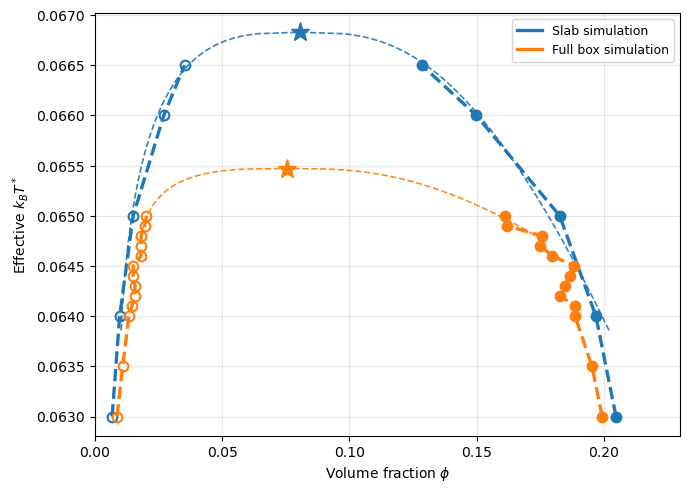

In [15]:
FOLDERS = ["Slab/Control", "Full_box/Control"]
LABELS  = ["Slab simulation", "Full box simulation"]
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
n_last_fit = [4, 3]

fig, ax, data = plot_volume_fractions(FOLDERS, labels=LABELS, phi_lim=(0, 0.23), use_blob=False,
                                      min_detected_frames=3, use_projected_values=True)

fits = fit_all_folders(data, n_last=n_last_fit, method="linear")                       # one row per folder
for fit, color in zip(fits, colors):
    main_ax, phi_c, T_c = plot_binodal_fit(ax, fit, color)
    print(f"For {fit["label"]}: critical temp. is {T_c} and critical fraction is {phi_c}.")

# # ax.legend(fontsize=8)
# fig.savefig("phase_diagram_slabvsbox.png", dpi=300, bbox_inches="tight")
# # plt.show()

In [94]:
display(fits[["label", "Tc", "Tc_err", "phi_c", "phi_c_err", "d", "s"]])

,label,Tc,Tc_err,phi_c,phi_c_err,d,s
0,Slab simulation,0.066829,0.000109,0.080606,0.119710,0.143836,8.607490
1,Full box simulation,0.068104,0.001067,0.086769,0.156773,0.064939,1.552128


### Slab control vs pol5 vs pol15

For temp 0.063 dilute v_f is: 0.0067199070369944
For temp 0.064 dilute v_f is: 0.0096791505353965
For temp 0.065 dilute v_f is: 0.0150059527593468
For temp 0.066 dilute v_f is: 0.0270190570208789
For temp 0.0665 dilute v_f is: 0.035187425699218
For temp 0.063 dilute v_f is: 0.0063883194953657
For temp 0.064 dilute v_f is: 0.008846675468649
For temp 0.065 dilute v_f is: 0.0130681555303506
For temp 0.066 dilute v_f is: 0.0200164672787992
For temp 0.0665 dilute v_f is: 0.0273382589800683
For temp 0.067 dilute v_f is: 0.0309418539983712
For temp 0.063 dilute v_f is: 0.0058393467678354
For temp 0.064 dilute v_f is: 0.0098404363184848
For temp 0.065 dilute v_f is: 0.0130471182542956
For temp 0.066 dilute v_f is: 0.0187719894550267
For temp 0.0665 dilute v_f is: 0.0217664772211054
For temp 0.067 dilute v_f is: 0.0310567849177712
For Slab control: critical temp. is 0.066828872536696 and critical fraction is 0.08060555816242565.
For Short polymers $(N_{mon}=5)$: critical temp. is 0.067521486602

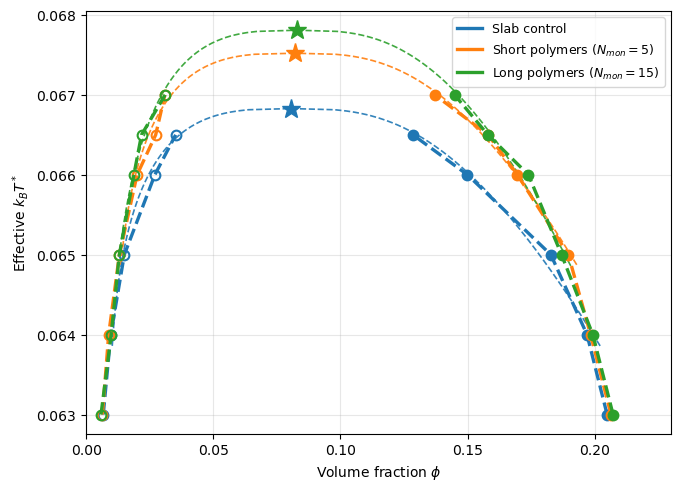

In [5]:
FOLDERS = ["Slab/Control", "Slab/Reg_pol_5/Phase_sep", "Slab/Reg_pol_15"]
LABELS  = ["Slab control", r"Short polymers $(N_{mon}=5)$", r"Long polymers $(N_{mon}=15)$"]
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
n_last_fit = 4

fig, ax, data = plot_volume_fractions(FOLDERS, labels=LABELS, phi_lim=(0, 0.23), use_blob=False, min_detected_frames=4)
fits = fit_all_folders(data, n_last=n_last_fit, method="linear")                       # one row per folder
for fit, color in zip(fits, colors):
    main_ax, phi_c, T_c = plot_binodal_fit(ax, fit, color)
    print(f"For {fit["label"]}: critical temp. is {T_c} and critical fraction is {phi_c}.")
    
# ax.legend(fontsize=8)
fig.savefig("phase_diagram_slabvspol5vspol15.png", dpi=300, bbox_inches="tight")
# plt.show()

In [6]:
### Get fraction inside of polymers for every temp analyzed

def collect_species_high_vf(folder, base_dir=".", species_index=2,
                            species_name=None, skip_marker="SKIP"):
    """
    Dense volume fraction of one species from the slab summaries of a folder.

    Reads every {traj}_density_summary.csv under `folder` and takes one row:
    species_name when given, otherwise the species_index-th species ordered by
    typeid (0-based, so 2 is the third).  Files with fewer species, or without
    the named one, are reported and skipped, as is any path containing
    skip_marker.
    """
    folder_path = Path(base_dir) / folder
    if not folder_path.is_dir():
        raise FileNotFoundError(f"No such folder: {folder_path}")

    rows = []
    for csv_path in sorted(folder_path.rglob("*_density_summary.csv")):
        relative = csv_path.relative_to(folder_path)
        if skip_marker and skip_marker in str(relative):
            print(f"skipped ({skip_marker} in path): {relative}")
            continue

        table = pd.read_csv(csv_path)
        if "typeid" in table.columns:
            table = table.sort_values("typeid")

        if species_name is not None:
            match = table[table.get("type_name", "") == species_name]
            if match.empty:
                print(f"no species {species_name!r} in {relative}")
                continue
            row = match.iloc[0]
        else:
            if len(table) <= species_index:
                print(f"only {len(table)} species in {relative}, "
                      f"need index {species_index}")
                continue
            row = table.iloc[species_index]

        rows.append({
            "kT": row.get("kT_kJ_per_mol", np.nan),
            "typeid": row.get("typeid", np.nan),
            "type_name": row.get("type_name", ""),
            "high_vf": row.get("high_vf_mean", np.nan),
            "high_vf_std": row.get("high_vf_std", np.nan),
            "low_vf": row.get("low_vf_mean", np.nan),
            "trajname": row.get("trajname", csv_path.stem),
            "source": str(csv_path),
        })

    if not rows:
        raise FileNotFoundError(f"No usable *_density_summary.csv under {folder_path}")
    return pd.DataFrame(rows).sort_values("kT").reset_index(drop=True)


def _pool(values, stds):
    values = np.asarray(values, dtype=float)
    stds = np.asarray(stds, dtype=float)
    good = np.isfinite(values)
    if not np.any(good):
        return np.nan, np.nan
    values, stds = values[good], stds[good]
    within = np.nanmean(stds ** 2) if np.any(np.isfinite(stds)) else 0.0
    between = np.var(values, ddof=1) if values.size > 1 else 0.0
    return float(np.mean(values)), float(np.sqrt(np.nan_to_num(within) + between))


def plot_species_high_vf(
    folders,
    base_dir=".",
    labels=None,
    species_index=2,
    species_name=None,
    skip_marker="SKIP",
    connect=True,
    figsize=(7.0, 5.0),
    colors=None,
    markers=("o", "s", "^", "D", "v", "P", "X", "*"),
    ax=None,
):
    """
    Dense volume fraction of one species against temperature, N folders.

    One color and marker per folder, error bars from the frame-to-frame std,
    trajectories sharing a temperature pooled into one point.

    Returns (fig, ax, data).
    """
    if isinstance(folders, (str, Path)):
        folders = [folders]
    folders = list(folders)
    if labels is None:
        labels = [Path(f).name for f in folders]
    if colors is None:
        cycle = plt.rcParams["axes.prop_cycle"].by_key()["color"]
        colors = [cycle[i % len(cycle)] for i in range(len(folders))]

    collected = []
    for folder, label in zip(folders, labels):
        part = collect_species_high_vf(folder, base_dir=base_dir,
                                       species_index=species_index,
                                       species_name=species_name,
                                       skip_marker=skip_marker)
        part["folder"] = str(folder)
        part["label"] = label
        collected.append(part)
    data = pd.concat(collected, ignore_index=True)

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    for i, label in enumerate(labels):
        subset = data[data["label"] == label]
        points = []
        for kT, group in subset.groupby("kT", sort=True):
            value, error = _pool(group["high_vf"], group["high_vf_std"])
            if np.isfinite(value):
                points.append((kT, value, error))
        if not points:
            print(f"{label}: nothing to plot")
            continue
        x, y, err = (np.array(v) for v in zip(*points))
        ax.errorbar(x, y, yerr=err,
                    marker=markers[i % len(markers)], markersize=6,
                    linestyle="-" if connect else "none", linewidth=1.2,
                    color=colors[i], capsize=3, label=label)

    plt.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
    names = sorted(set(data["type_name"].dropna()))
    ax.set_xlabel(r"Effective $k_BT^*$")
    ax.set_ylabel(r"Dense volume fraction of polymer beads")
    if len(names) > 1:
        print(f"note: the selected species differs between folders: {names}")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)
    fig.tight_layout()
    return fig, ax, data

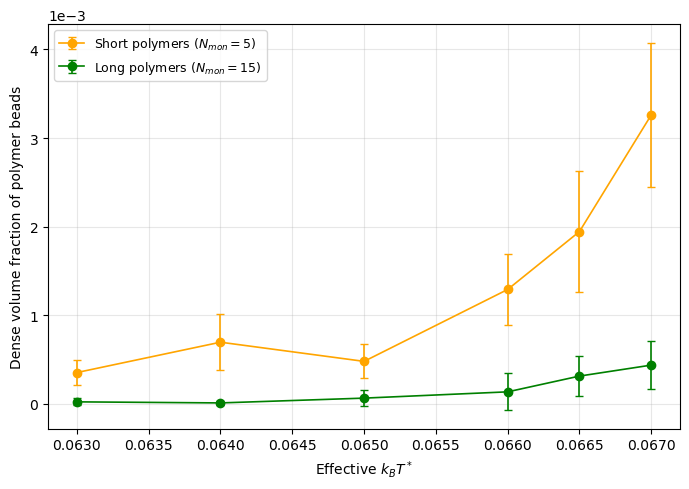

In [7]:
FOLDERS = ["Slab/Reg_pol_5/Phase_sep", "Slab/Reg_pol_15"]
LABELS  = [r"Short polymers $(N_{mon}=5)$", r"Long polymers $(N_{mon}=15)$"]

fig, ax, data = plot_species_high_vf(FOLDERS, labels=LABELS, species_index=2, colors=('orange', 'green'), markers=('o', 'o'))

### Slab pol5 1% vs pol5 3%

### Slab control vs patchy pol 30 length (pattern: core,core,patchy)

For temp 0.063 dilute v_f is: 0.0067199070369944
For temp 0.064 dilute v_f is: 0.0096791505353965
For temp 0.065 dilute v_f is: 0.0150059527593468
For temp 0.066 dilute v_f is: 0.0270190570208789
For temp 0.0665 dilute v_f is: 0.035187425699218
For temp 0.063 dilute v_f is: 0.0065744492996999
For temp 0.064 dilute v_f is: 0.0095376998983029
For temp 0.065 dilute v_f is: 0.0153968818121331
For temp 0.066 dilute v_f is: 0.024140957301546
For temp 0.0665 dilute v_f is: 0.0362876983547799
skipped (detected in 3/? frames): elongation_kT_0.067_traj_density_summary.csv
For Slab control: critical temp. is 0.066828872536696 and critical fraction is 0.08060555816242565.
For Patchy polymers: critical temp. is 0.06687831661053162 and critical fraction is 0.07073812221427195.


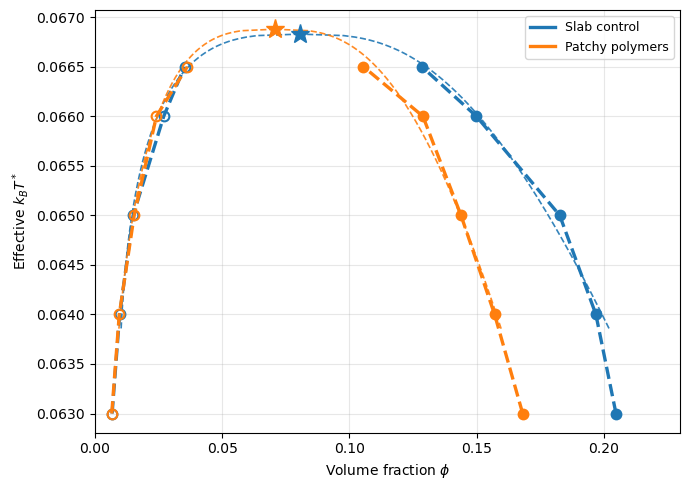

In [8]:
FOLDERS = ["Slab/Control", "Slab/Reg_pol_with_patch"]
LABELS  = ["Slab control", r"Patchy polymers"]
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
n_last_fit = 4

fig, ax, data = plot_volume_fractions(FOLDERS, labels=LABELS, phi_lim=(0, 0.23), use_blob=False,
                                      min_detected_frames=4, use_projected_values=True)

fits = fit_all_folders(data, n_last=n_last_fit, method="linear")                       # one row per folder
for fit, color in zip(fits, colors):
    main_ax, phi_c, T_c = plot_binodal_fit(ax, fit, color)
    print(f"For {fit["label"]}: critical temp. is {T_c} and critical fraction is {phi_c}.")
    
# ax.legend(fontsize=8)
fig.savefig("phase_diagram_slabvspatchypol.png", dpi=300, bbox_inches="tight")
# plt.show()

### Droplet control vs LJ 0.05

For temp 0.063 dense v_f is: 0.1994063150002438
For temp 0.0635 dense v_f is: 0.1953814575746655
For temp 0.064 dense v_f is: 0.1887560169589979
For temp 0.0641 dense v_f is: 0.188900044024011
For temp 0.0642 dense v_f is: 0.1828748497958185
For temp 0.0643 dense v_f is: 0.1847477793468043
For temp 0.0644 dense v_f is: 0.1866739975203845
For temp 0.0645 dense v_f is: 0.1883341619708978
For temp 0.0646 dense v_f is: 0.1798640064756106
For temp 0.0647 dense v_f is: 0.1751154602912492
For temp 0.0648 dense v_f is: 0.1755908214983264
For temp 0.0649 dense v_f is: 0.1620023729462197
skipped (detected in 0/10 frames): elongation_kT_0.0651_traj_type_2_3PPB_core_density3d_summary.csv
skipped (detected in 0/10 frames): elongation_kT_0.0652_traj_type_2_3PPB_core_density3d_summary.csv
skipped (detected in 0/10 frames): elongation_kT_0.0653_traj_type_2_3PPB_core_density3d_summary.csv
skipped (detected in 0/10 frames): elongation_kT_0.0655_traj_type_2_3PPB_core_density3d_summary.csv
For temp 0.065 

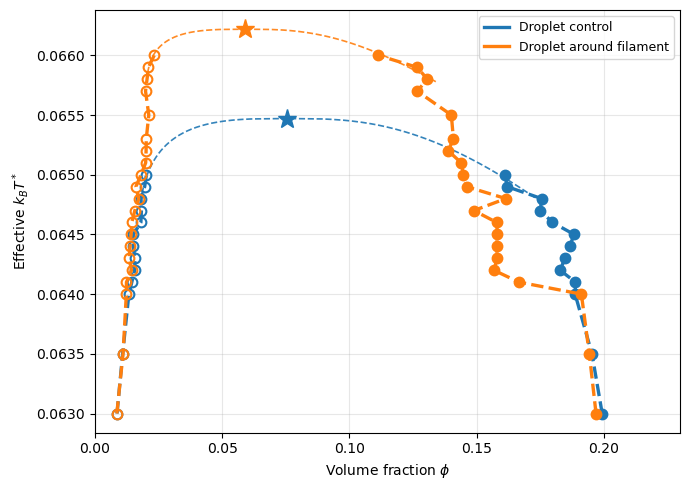

In [5]:
# TODO: make a new folder for the wetting regime so that we have 3 critical temps in the plot
# Only after checking with the volume as well (should have 2 regions there as well: linear decay, stagnant, drop to 0)

FOLDERS = ["Full_box/Control", "Full_box/LJ_force/LJ_0.05"]
LABELS  = ["Droplet control", r"Droplet around filament"]
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
n_last_fit = 3

fig, ax, data = plot_volume_fractions(FOLDERS, labels=LABELS, phi_lim=(0, 0.23), use_blob=False,
                                      min_detected_frames=3, use_projected_values=True)

fits = fit_all_folders(data, n_last=n_last_fit, method="linear")                       # one row per folder
for fit, color in zip(fits, colors):
    main_ax, phi_c, T_c = plot_binodal_fit(ax, fit, color)
    print(f"For {fit["label"]}: critical temp. is {T_c} and critical fraction is {phi_c}.")
# ax.legend(fontsize=8)
fig.savefig("phase_diagram_dropletctrlvslj.png", dpi=300, bbox_inches="tight")
# plt.show()

## Phase preference graphs

In [6]:
BLUE_TO_RED = LinearSegmentedColormap.from_list("blue_to_red", ["blue", "red"])


def _temperature(profile_df, path):
    """kT from the CSV's kT_kJ_per_mol column, else the 2nd-to-last '_' item of the file stem."""
    if "kT_kJ_per_mol" in profile_df.columns:
        kT = pd.to_numeric(profile_df["kT_kJ_per_mol"], errors="coerce").dropna()
        if len(kT):
            return float(kT.iloc[0])
    stem = path.name[: -len("_density.csv")]          # "<xxx>_<xxx>_<temp>_traj"
    parts = stem.split("_")
    try:
        return float(parts[-2])
    except (IndexError, ValueError):
        return np.nan


def load_slab_profiles(folders, skip_keyword="SKIP"):
    """
    Find every *_density.csv under `folders` (one path or a list), searching
    subfolders too, and return a list of dicts sorted by temperature:
        {"kT", "profile" (DataFrame), "summary" (DataFrame or None), "path"}
    Files whose path contains `skip_keyword` are ignored.
    """
    if isinstance(folders, (str, Path)):
        folders = [folders]
    runs = []
    for folder in folders:
        for path in sorted(Path(folder).rglob("*_density.csv")):
            if skip_keyword and skip_keyword in str(path):
                continue
            profile = pd.read_csv(path)
            summary_path = path.with_name(path.name.replace("_density.csv", "_density_summary.csv"))
            summary = pd.read_csv(summary_path) if summary_path.exists() else None
            kT = _temperature(profile, path)
            if not np.isfinite(kT):
                print(f"Skipping {path}: no temperature found")
                continue
            runs.append({"kT": kT, "profile": profile, "summary": summary, "path": path})
    runs.sort(key=lambda run: run["kT"])
    return runs


def combine_bounds(runs, mode="avg_bounds"):
    """
    One set of slab bounds from the reference (first) species of every summary.

    mode="avg_bounds": the mean of each bound over all temperatures.
    mode="min_bounds": the narrowest region: min x_in_max and buffer_min,
                       max x_in_min and buffer_max.
    Returns dict(x_in_min, x_in_max, buffer_min, buffer_max), or None.
    """
    keys = ("x_in_min", "x_in_max", "buffer_min", "buffer_max")
    rows = [run["summary"].iloc[0] for run in runs
            if run["summary"] is not None and len(run["summary"])]
    if not rows:
        return None
    values = {k: np.array([float(row[k]) for row in rows], dtype=float) for k in keys}
    if mode == "avg_bounds":
        return {k: float(np.nanmean(v)) for k, v in values.items()}
    if mode == "min_bounds":
        return {
            "x_in_min": float(np.nanmax(values["x_in_min"])),
            "x_in_max": float(np.nanmin(values["x_in_max"])),
            "buffer_min": float(np.nanmin(values["buffer_min"])),
            "buffer_max": float(np.nanmax(values["buffer_max"])),
        }
    raise ValueError("Mode must be 'avg_bounds' or 'min_bounds'")


def plot_slab_profiles(
    folders,
    column_indices,
    labels,
    bounds="avg_bounds",
    cmap=BLUE_TO_RED,
    colorbar_label=r"Effective temperature ($k_BT^*$)",
    xlabel="x [nm]",
    ylabel="Volume fraction",
    figsize=None,
    linewidth=1.2,
    dense_color="orchid",
    dilute_color="gray",
    shade_alpha=0.3,
    ylim=None,
    skip_keyword="SKIP",
    savepath=None,
    dpi=300,
):
    """
    One vertically stacked subplot per column of the *_density.csv files.

    folders        : folder or list of folders searched (with subfolders) for *_density.csv.
    column_indices : column positions in *_density.csv to plot (0 is x_nm), e.g. [1, 3].
    labels         : one label per column, shown as "Profile of {label}".
    bounds         : "avg_bounds", "min_bounds" (see combine_bounds) or None for no shading.
    Every temperature found is one curve, coloured blue (lowest) to red (highest),
    with a single colour bar to the right of the figure.
    Returns (fig, axes, runs).
    """
    column_indices = list(column_indices)
    labels = list(labels)
    if len(labels) != len(column_indices):
        raise ValueError("Give exactly one label per column index.")

    if isinstance(cmap, str):
        cmap = matplotlib.colormaps[cmap]

    runs = load_slab_profiles(folders, skip_keyword=skip_keyword)
    if not runs:
        raise FileNotFoundError(f"No *_density.csv files found under {folders}")

    temps = np.array([run["kT"] for run in runs])
    norm = Normalize(vmin=temps.min(), vmax=temps.max() if temps.max() > temps.min() else temps.min() + 1e-12)
    region = combine_bounds(runs, bounds) if bounds else None

    n = len(column_indices)
    if figsize is None:
        figsize = (6.0, 2.6 * n + 0.6)
    else:
        figsize = (figsize[0], 2.6 * n + 0.6)
            
    fig, axes = plt.subplots(n, 1, figsize=figsize, sharex=True, squeeze=False)
    axes = axes[:, 0]

    for ax, col, label in zip(axes, column_indices, labels):
        x_lo, x_hi = np.inf, -np.inf
        y_max = 0
        for run in runs:
            df = run["profile"]
            x = df.iloc[:, 0].to_numpy(dtype=float)
            y = pd.to_numeric(df.iloc[:, col], errors="coerce").to_numpy(dtype=float)
            ax.plot(x, y, color=cmap(norm(run["kT"])), lw=linewidth)
            x_lo, x_hi = min(x_lo, np.nanmin(x)), max(x_hi, np.nanmax(x))
            if np.nanmax(y) > y_max:
                y_max = np.nanmax(y)
        ax.set_xlim(x_lo, x_hi)

        if region is not None:
            # Shaded regions only: no edges, no vertical lines, no legend entries.
            span = dict(alpha=shade_alpha, lw=0, zorder=0)
            ax.axvspan(region["x_in_min"], region["x_in_max"], color=dense_color, **span)
            ax.axvspan(x_lo, region["buffer_min"], color=dilute_color, **span)
            ax.axvspan(region["buffer_max"], x_hi, color=dilute_color, **span)

        ax.text(0.98, 0.95, f"Profile of {label}", transform=ax.transAxes,
                ha="right", va="top", fontsize=9,
                bbox=dict(boxstyle="round", facecolor="white", edgecolor="0.6", alpha=0.9))
        ax.set_ylabel(ylabel)
        if ylim is not None:
            if ylim[1] > y_max:
                ax.set_ylim(*ylim)
        ax.grid(alpha=0.3)

    axes[-1].set_xlabel(xlabel)

    mappable = ScalarMappable(norm=norm, cmap=cmap)
    mappable.set_array(temps)
    cbar = fig.colorbar(mappable, ax=list(axes), location="right", fraction=0.04, pad=0.03)
    cbar.set_label(colorbar_label)

    if savepath is not None:
        fig.savefig(savepath, dpi=dpi, bbox_inches="tight")
    return fig, axes, runs

### Reg pol 5

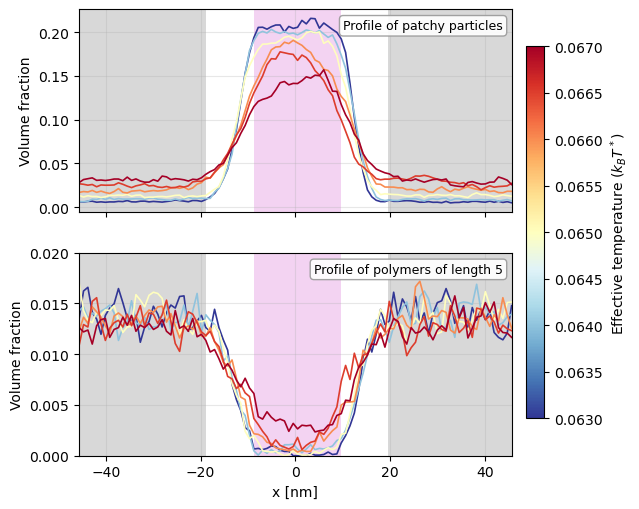

In [17]:
FOLDERS = ["Slab/Reg_pol_5/Phase_sep", ]
COLUMN_INDICES = [1, 5]
LABELS  = ["patchy particles", "polymers of length 5"]

fig, axes, runs = plot_slab_profiles(
    FOLDERS,                                    # one folder, or a list of folders
    column_indices=COLUMN_INDICES,              # columns of *_density.csv (0 is x_nm)
    labels=LABELS,                              # shown as "Profile of {label}"
    bounds="avg_bounds",                        # or "min_bounds", or None for no shading
    cmap="RdYlBu_r",
    figsize=(6.0, 0),
    ylim=(0.0, 0.020),
    savepath="regpol5_profiles.png",
)

### Reg pol 15

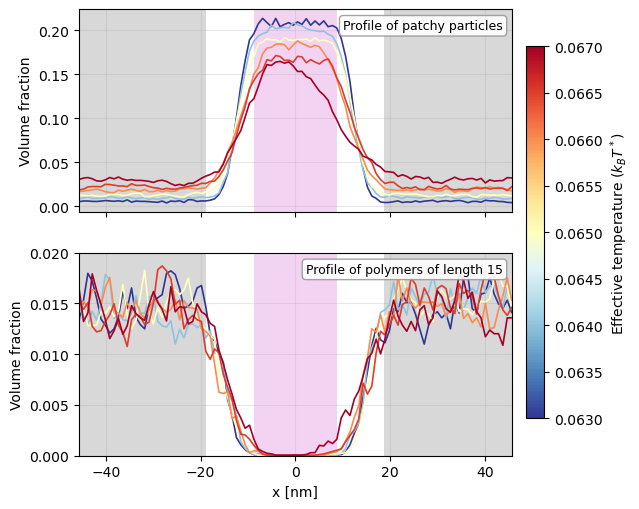

In [18]:
FOLDERS = ["Slab/Reg_pol_15", ]
COLUMN_INDICES = [1, 5]
LABELS  = ["patchy particles", "polymers of length 15"]

fig, axes, runs = plot_slab_profiles(
    FOLDERS,                                    # one folder, or a list of folders
    column_indices=COLUMN_INDICES,              # columns of *_density.csv (0 is x_nm)
    labels=LABELS,                              # shown as "Profile of {label}"
    bounds="avg_bounds",                        # or "min_bounds", or None for no shading
    cmap="RdYlBu_r",
    figsize=(6.0, 0),
    ylim=(0.0, 0.020),
    savepath="regpol15_profiles.png",
)

### Pathcy pol

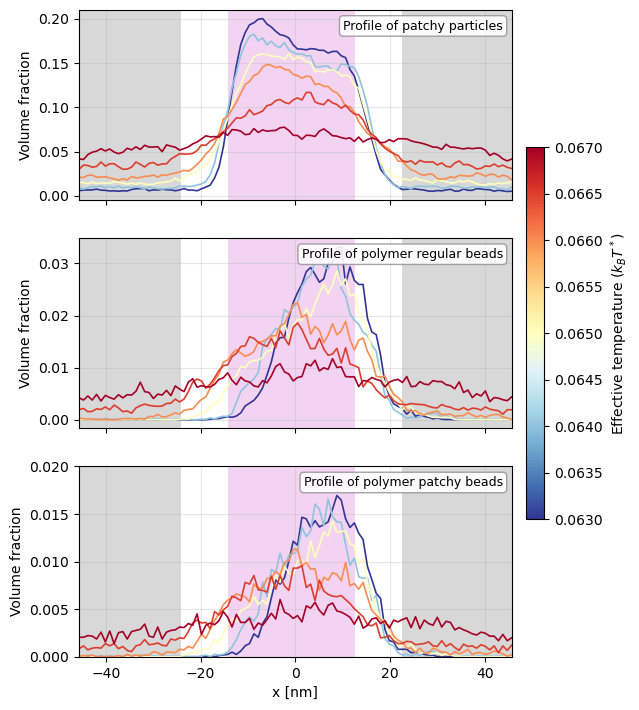

In [26]:
FOLDERS = ["Slab/Reg_pol_with_patch", ]
COLUMN_INDICES = [1, 5, 7]
LABELS  = ["patchy particles", "polymer regular beads", "polymer patchy beads"]

fig, axes, runs = plot_slab_profiles(
    FOLDERS,                                    # one folder, or a list of folders
    column_indices=COLUMN_INDICES,              # columns of *_density.csv (0 is x_nm)
    labels=LABELS,                              # shown as "Profile of {label}"
    bounds="avg_bounds",                        # or "min_bounds", or None for no shading
    cmap="RdYlBu_r",
    figsize=(6.0, 0),
    ylim=(0.0, 0.020),
    savepath="patchypolslab_profiles.png",
)

## Quality of equilibration (for short vs long simulations)

In [4]:
def collect_run_metrics(folder, base_dir=".", long_marker="LONG",
                        droplet_volume="isosurface", skip_marker="SKIP",
                        min_detected_frames=3, use_projected_values=True, verbose=True):
    """
    Dense/dilute fractions, condensate volume and aspect ratio per trajectory.

    Same file discovery as collect_volume_fractions: "Slab" in the folder name
    picks {traj}_density_summary.csv, anything else the 3D
    {traj}_type_*_density3d_summary.csv, taking the first species either way.

    Adds, per trajectory:
      volume      - the isosurface volume for droplets (droplet_volume="cuboid"
                    switches to the cuboid one), the slab volume for slabs
      aspect      - H_z / W_xy, droplets only; NaN for slabs
      is_long     - whether long_marker appears in the trajectory name or file

    Dense values use dense_vf_cuboid_pol_corrected when a polymer is present,
    as elsewhere.
    """
    folder_path = Path(base_dir) / folder
    if not folder_path.is_dir():
        raise FileNotFoundError(f"No such folder: {folder_path}")

    is_slab = "slab" in str(folder).lower()
    pattern = "*_density_summary.csv" if is_slab else "*_density3d_summary.csv"

    volume_column = {
        "isosurface": "condensate_volume_isosurface_nm3",
        "cuboid": "condensate_volume_nm3",
    }[droplet_volume]

    rows = []
    for csv_path in sorted(folder_path.rglob(pattern)):
        if skip_marker and skip_marker in str(csv_path.relative_to(folder_path)):
            continue
        table = pd.read_csv(csv_path)
        if table.empty:
            continue
        row = (table.sort_values("typeid").iloc[0]
               if "typeid" in table.columns else table.iloc[0])
        
        # A trajectory where the condensate was never detected has fallen back
        # to averaging every frame, so its numbers describe no particular phase.
        n_detected = row.get("n_frames_detected", np.nan)
        if np.isfinite(n_detected) and n_detected < min_detected_frames:
            if verbose:
                n_total = row.get("n_frames_analysed", row.get("frames_used", "?"))
                print(f"skipped (detected in {int(n_detected)}/{n_total} frames): {csv_path.name}")
            continue

        dense = row.get("high_vf_mean", np.nan)
        dense_std = row.get("high_vf_std", np.nan)
        dilute = row.get("low_vf_mean", np.nan)
        dilute_std = row.get("low_vf_std", np.nan)
        polymer = bool(row.get("polymer_present", False))
        if not is_slab and polymer:
            corrected = row.get("dense_vf_cuboid_pol_corrected", np.nan)
            if np.isfinite(corrected):
                dense = corrected
                dense_std = row.get("dense_vf_cuboid_pol_corrected_std", dense_std)
            if use_projected_values:
                dense = row.get("projected_dense_vf", np.nan)
                dense_std = row.get("projected_dense_vf_std", np.nan)
                dilute = row.get("projected_dilute_vf", np.nan)
                dilute_std = row.get("projected_dilute_vf_std", np.nan)

        if is_slab:
            volume = row.get("dense_volume_nm3", np.nan)
            volume_std = row.get("dense_volume_nm3_std", np.nan)
            aspect = aspect_std = np.nan
        else:
            volume = row.get(volume_column, np.nan)
            volume_std = row.get(f"{volume_column}_std", np.nan)
            aspect = row.get("aspect_ratio (H_z/W_xy)", np.nan)
            aspect_std = row.get("aspect_ratio_std", np.nan)

        phi_box = row.get("whole_box_vf", np.nan)
        box_volume = row.get("box_volume_nm3", np.nan)
        if is_slab and not np.isfinite(box_volume):
            # Slab summaries have no box volume: Ly*Lz = dense volume / width, and
            # box_left/box_right are the outer bin centres, so Lx = span * n/(n-1).
            width = row.get("x_width_nm", np.nan)
            n_bins = row.get("n_bins", np.nan)
            span = row.get("box_right", np.nan) - row.get("box_left", np.nan)
            if np.isfinite(width) and width > 0 and np.isfinite(n_bins) and n_bins > 1:
                box_volume = volume / width * span * n_bins / (n_bins - 1)
                
        trajname = str(row.get("trajname", csv_path.stem))
        rows.append({
            "trajname": trajname,
            "kT": row.get("kT_kJ_per_mol", np.nan),
            "geometry": "slab" if is_slab else "droplet",
            "polymer_present": polymer,
            "is_long": (long_marker in trajname)
                        or (long_marker in csv_path.name)
                        or (long_marker in csv_path.parent.name),
            "high_vf": dense, "high_vf_std": dense_std,
            "low_vf": dilute, "low_vf_std": dilute_std,
            "volume": volume, "volume_std": volume_std,
            "phi_box": phi_box, "box_volume": box_volume,
            "aspect": aspect, "aspect_std": aspect_std,
            "n_frames_detected": n_detected,
            "source": str(csv_path),
        })

    if not rows:
        raise FileNotFoundError(f"No {pattern} files under {folder_path}")
    return pd.DataFrame(rows)


def _pool(values, stds):
    """One value and one error bar from possibly several trajectories."""
    values = np.asarray(values, dtype=float)
    stds = np.asarray(stds, dtype=float)
    good = np.isfinite(values)
    if not np.any(good):
        return np.nan, np.nan
    values, stds = values[good], stds[good]
    mean = float(np.mean(values))
    within = np.nanmean(stds ** 2) if np.any(np.isfinite(stds)) else 0.0
    between = np.var(values, ddof=1) if values.size > 1 else 0.0
    return mean, float(np.sqrt(np.nan_to_num(within) + between))


def plot_timescale_comparison(
    folders,
    base_dir=".",
    labels=None,
    long_marker="LONG",
    droplet_volume="isosurface",
    short_label="Normal time",
    long_label="Long time (10x)",
    figsize=(7.5, 13.5),
    colors=("#4C72B0", "#DD8452"),
    log_low_vf=False,
    min_detected_frames=3,
    use_projected_values=True,
):
    """
    Short versus long runs, for up to three folders, as four stacked bar panels.

    Panels, top to bottom: dense volume fraction, dilute volume fraction,
    condensate volume, aspect ratio.  Each panel has one section per folder and
    two bars per section, short then long, with the frame-to-frame std as the
    error bar.  Slab folders have no aspect ratio, so that section is marked
    n/a instead of being drawn.

    Returns (fig, axes, data), the data being every trajectory found, so the
    numbers behind the bars stay inspectable.
    """
    if isinstance(folders, (str, Path)):
        folders = [folders]
    folders = list(folders)
    if labels is None:
        labels = [Path(f).name for f in folders]

    collected = []
    for folder, label in zip(folders, labels):
        part = collect_run_metrics(folder, base_dir=base_dir,
                                   long_marker=long_marker,
                                   droplet_volume=droplet_volume,
                                   use_projected_values=use_projected_values,
                                   min_detected_frames=min_detected_frames)
        part["folder"] = str(folder)
        part["label"] = label
        collected.append(part)
    data = pd.concat(collected, ignore_index=True)

    panels = [
        ("n_frames_detected", None, "Number of frames with condensate", False),
        ("high_vf", "high_vf_std", "Dense volume fraction", False),
        ("low_vf", "low_vf_std", "Dilute volume fraction", log_low_vf),
        ("volume", "volume_std", "Condensate volume [nm$^3$]", False),
        ("aspect", "aspect_std", "Aspect ratio $H_z/W_{xy}$", False),
    ]

    fig, axes = plt.subplots(len(panels), 1, figsize=figsize, sharex=True)
    width = 0.36
    centers = np.arange(len(labels))

    for ax, (column, std_column, ylabel, log_scale) in zip(axes, panels):
        for offset, is_long, color, series_label in (
            (-width / 2, False, colors[0], short_label),
            (+width / 2, True, colors[1], long_label),
        ):
            heights, errors, positions = [], [], []
            for i, label in enumerate(labels):
                subset = data[(data["label"] == label) & (data["is_long"] == is_long)]
                if std_column is None:
                    values = pd.to_numeric(subset[column], errors="coerce")
                    value = float(values.mean()) if values.notna().any() else np.nan
                    error = np.nan
                else:
                    value, error = _pool(subset[column], subset[std_column])
                heights.append(value)
                errors.append(error)
                positions.append(centers[i] + offset)

            ax.bar(positions, heights, width=width,
                   yerr=None if std_column is None else errors,
                   capsize=4, color=color, edgecolor="black",
                   linewidth=0.6, label=series_label, zorder=2)

        # Mark sections that have nothing to show, e.g. a slab's aspect ratio.
        for i, label in enumerate(labels):
            if not np.any(np.isfinite(data.loc[data["label"] == label, column])):
                ax.text(centers[i], 0.5, "n/a", ha="center", va="center",
                        transform=ax.get_xaxis_transform(),
                        fontsize=10, color="grey", style="italic")

        ax.set_ylabel(ylabel)
        ax.grid(axis="y", alpha=0.3, zorder=0)
        if log_scale:
            ax.set_yscale("log")

    axes[0].yaxis.set_major_locator(MaxNLocator(integer=True))
    axes[0].legend(fontsize=9, ncol=2)
    axes[-1].set_xticks(centers)
    axes[-1].set_xticklabels(labels)
    fig.tight_layout()

    return fig, axes, data

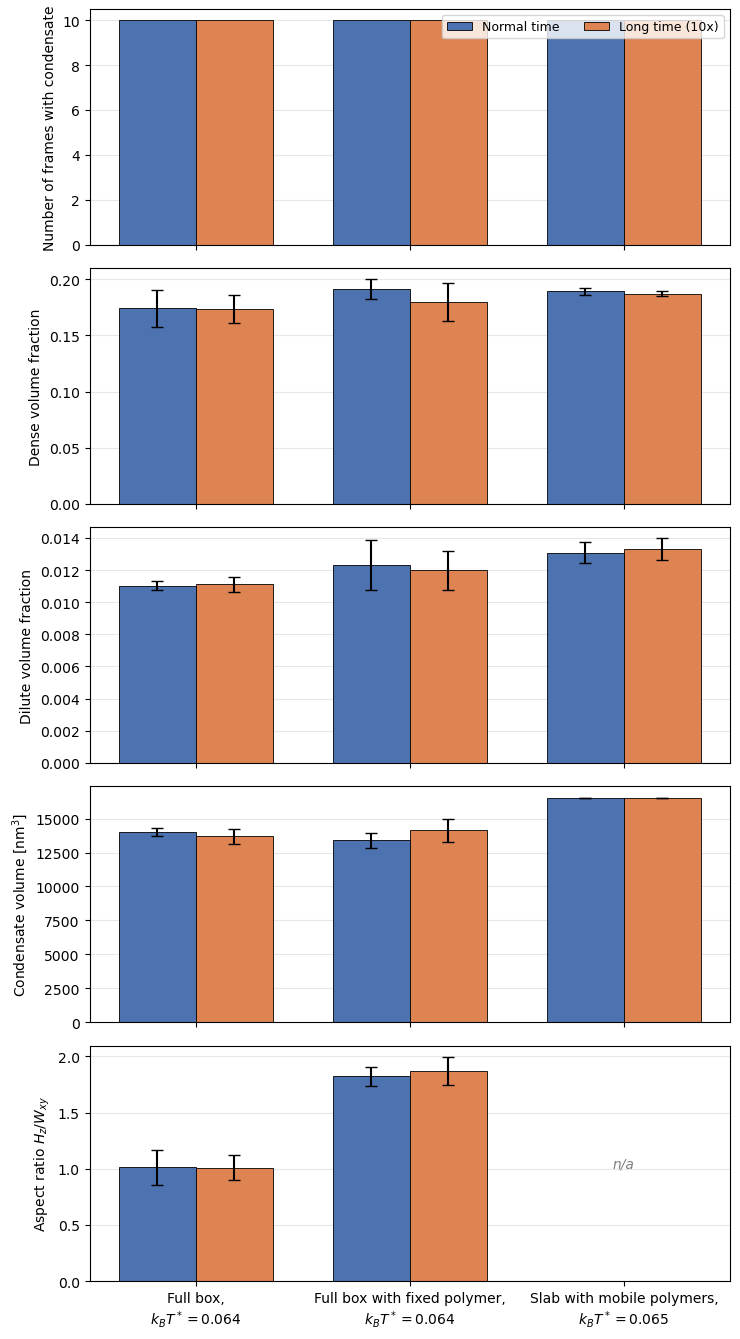

In [29]:
FOLDERS = ["Short_long/Full_box_control", "Short_long/Full_box_lj0.05_0.064", "Short_long/Slab_regpol5"]
LABELS  = ["Full box,\n$k_BT^*=0.064$", "Full box with fixed polymer,\n$k_BT^*=0.064$", "Slab with mobile polymers,\n$k_BT^*=0.065$"]

fig, axes, data = plot_timescale_comparison(FOLDERS, labels=LABELS, use_projected_values=True, min_detected_frames=0)
data[["label", "trajname", "is_long", "high_vf", "low_vf", "volume", "aspect"]]
fig.savefig("shortvslongtime.png", dpi=300, bbox_inches="tight")

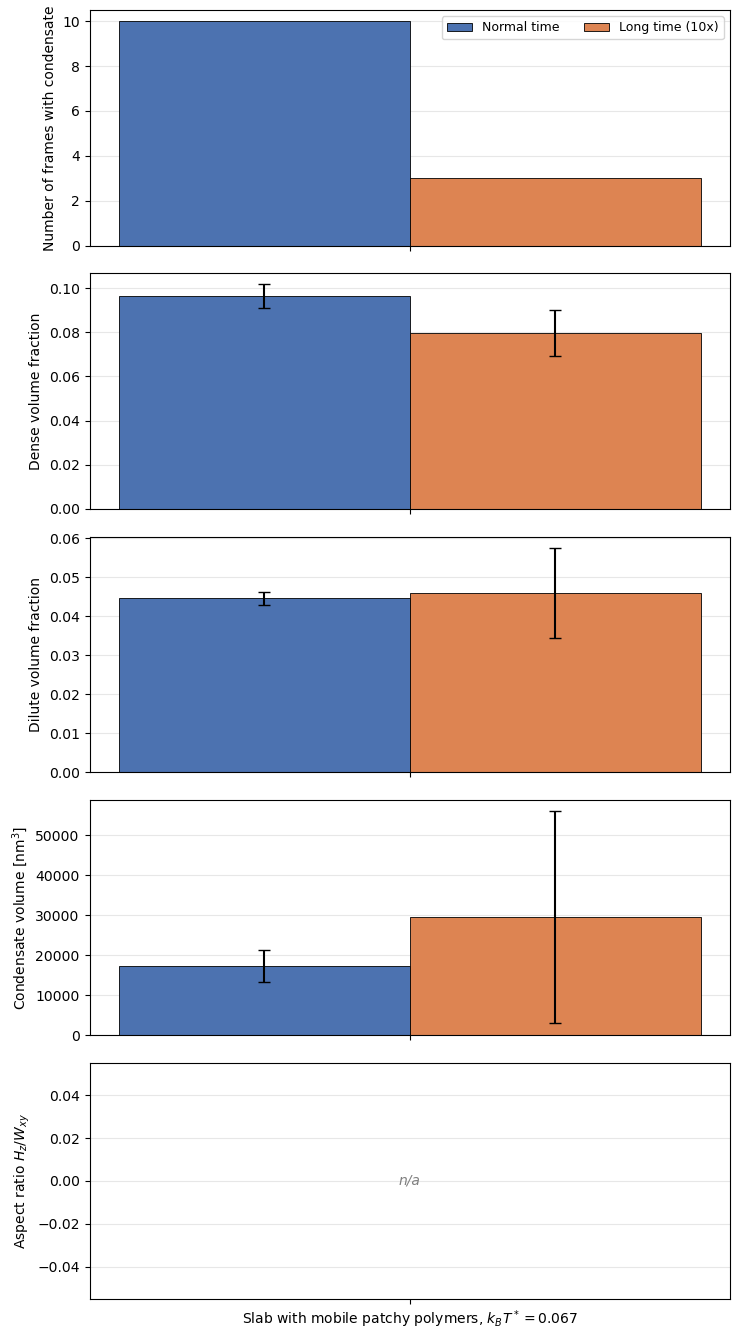

In [28]:
FOLDERS = ["Short_long/Slab_bigpatchypol"]
LABELS  = [r"Slab with mobile patchy polymers, $k_BT^*=0.067$"]

fig, axes, data = plot_timescale_comparison(FOLDERS, labels=LABELS, use_projected_values=True, min_detected_frames=0)
data[["label", "trajname", "is_long", "high_vf", "low_vf", "volume", "aspect"]]
fig.savefig("shortvslongtime_critical.png", dpi=300, bbox_inches="tight")

### Observables plotting (for short simulations)

In [5]:
"""
Equilibration check: kinetic temperature, potential energy and pressure
against time from the *_observables.csv written by analysis_last.py.
"""
def find_observables(folder, contains=None, skip_keyword="SKIP"):
    """The *_observables.csv files under folder (subfolders too), minus skipped ones."""
    folder = Path(folder)
    files = []
    for path in sorted(folder.rglob("*_observables.csv")):
        if skip_keyword and skip_keyword in str(path.relative_to(folder)):
            continue
        if contains and contains not in path.name:
            continue
        files.append(path)
    return files


def plot_equilibration(
    folders,
    labels,
    colors=None,
    tail_fraction=0.2,
    time_column="time_ps",
    obs_contains=None,
    show_legend=True,
    skip_keyword="SKIP",
    figsize=(8.0, 8.0),
    linewidth=1.0,
    savepath=None,
    dpi=300,
):
    """
    Three stacked panels sharing the time axis: kinetic temperature, potential
    energy and pressure, one colour per folder, values plotted as recorded.

    The mean over the last tail_fraction of the time points is drawn as a dotted
    line of the folder's colour, only over that final stretch, without a legend
    entry.  Each folder should hold one *_observables.csv; if it holds several,
    the first is used (pass obs_contains, e.g. "kT_0.064", to pick one).
    time_column="step" plots against the timestep instead of time.
    Returns (fig, axes, tail_means) with the plateau values per folder.
    """
    folders = list(folders)
    labels = list(labels)
    if len(labels) != len(folders):
        raise ValueError("Give exactly one label per folder.")
    if colors is None:
        colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

    panels = (
        ("kinetic_temperature", r"Effective thermal energy $k_BT^*$"),
        ("potential_energy", "Potential energy [kJ/mol]"),
        ("pressure", r"Pressure [kJ/(mol nm$^3$)]"),
    )
    fig, axes = plt.subplots(len(panels), 1, figsize=figsize, sharex=True, layout="constrained")

    rows = []
    for k, (folder, label) in enumerate(zip(folders, labels)):
        files = find_observables(folder, obs_contains, skip_keyword)
        if not files:
            print(f"{label}: no *_observables.csv found")
            continue
        if len(files) > 1:
            print(f"{label}: {len(files)} observables files, using {files[0].name} "
                  "(pass obs_contains to choose)")
        obs = pd.read_csv(files[0])
        if time_column not in obs.columns:
            raise KeyError(f"{files[0]} has no column {time_column!r}")
        obs = obs.sort_values(time_column)
        t = pd.to_numeric(obs[time_column], errors="coerce").to_numpy(dtype=float)
        n_tail = max(1, int(np.ceil(tail_fraction * len(t))))
        color = colors[k % len(colors)]

        record = {"folder": str(folder), "label": label, "file": str(files[0]),
                  "tail_start": t[-n_tail], "tail_end": t[-1], "n_tail_points": n_tail}
        for ax, (column, ylabel) in zip(axes, panels):
            if column not in obs.columns:
                continue
            y = pd.to_numeric(obs[column], errors="coerce").to_numpy(dtype=float)
            ax.plot(t, y, color=color, lw=linewidth, label=label if ax is axes[0] else None)
            tail = y[-n_tail:]
            mean = float(np.nanmean(tail)) if np.any(np.isfinite(tail)) else np.nan
            if np.isfinite(mean):
                ax.hlines(mean, t[-n_tail], t[-1], colors=color, linestyles="--", linewidth=2.5, zorder=3)
            record[f"{column}_tail_mean"] = mean
            record[f"{column}_tail_std"] = float(np.nanstd(tail, ddof=1)) if np.sum(np.isfinite(tail)) > 1 else np.nan
            ax.set_ylabel(ylabel)
        rows.append(record)

    for ax in axes:
        ax.grid(alpha=0.3)
    axes[-1].set_xlabel("time [ps]" if time_column == "time_ps" else time_column)
    if show_legend:
        axes[0].legend(fontsize=9, loc="upper left")

    if savepath is not None:
        fig.savefig(savepath, dpi=dpi, bbox_inches="tight")
    return fig, axes, pd.DataFrame(rows)

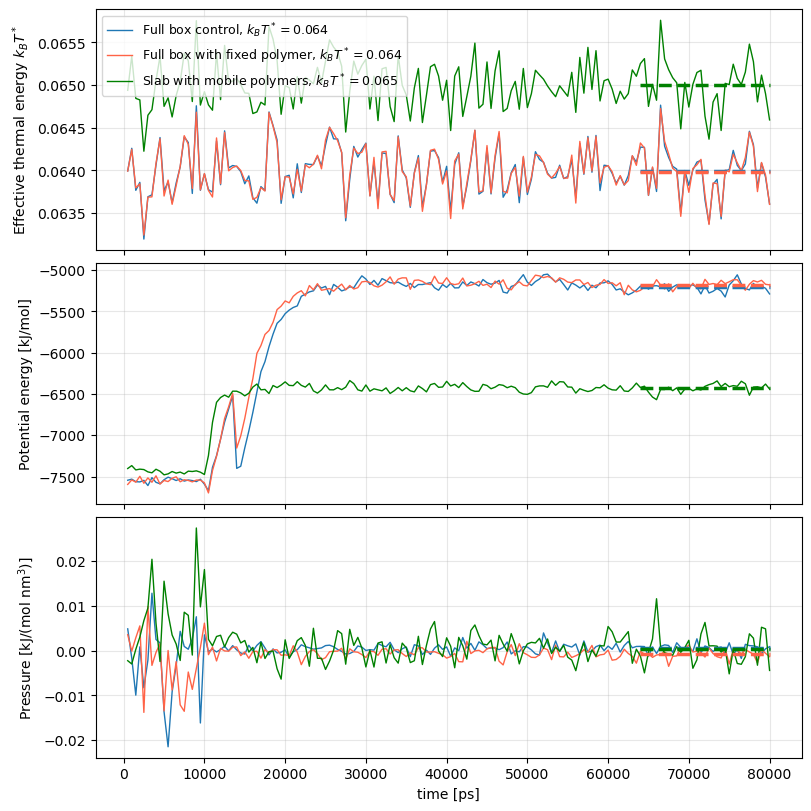

In [39]:
FOLDERS = ["Short_long/Full_box_control/0.064", "Short_long/Full_box_lj0.05_0.064/LJ0.05", "Short_long/Slab_regpol5/0.065"]
LABELS  = [r"Full box control, $k_BT^*=0.064$", r"Full box with fixed polymer, $k_BT^*=0.064$", r"Slab with mobile polymers, $k_BT^*=0.065$"]
COLORS = ["#1f77b4", "tomato", "green"]


fig, axes, plateau = plot_equilibration(
    FOLDERS,
    labels=LABELS,
    colors=COLORS,
    savepath="observables_short.png",
)

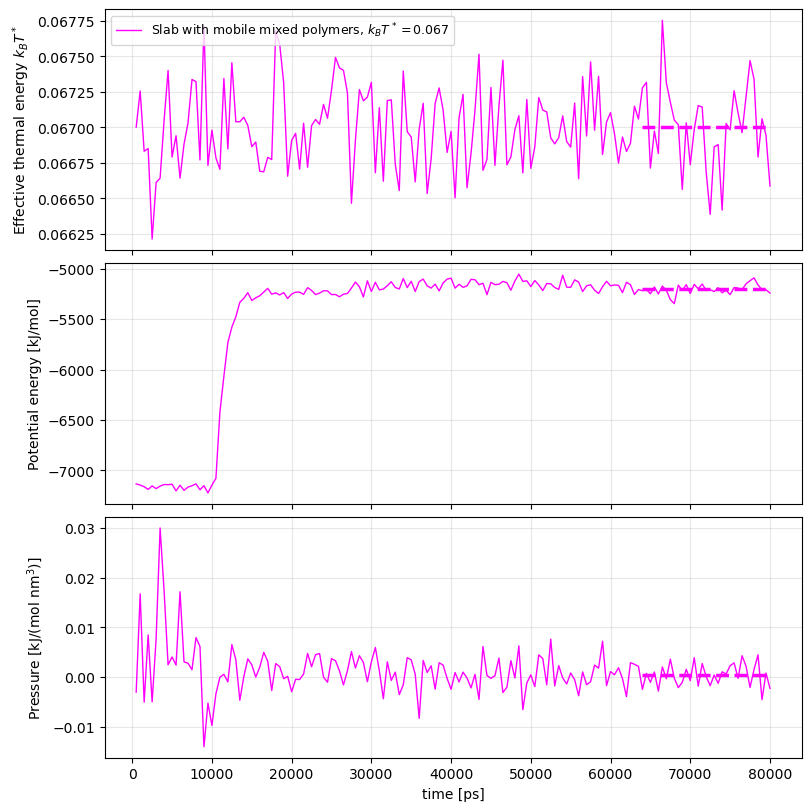

In [40]:
FOLDERS = ["Short_long/Slab_bigpatchypol/0.067_short"]
LABELS  = [r"Slab with mobile mixed polymers, $k_BT^*=0.067$"]
COLORS = ["magenta"]


fig, axes, plateau = plot_equilibration(
    FOLDERS,
    labels=LABELS,
    colors=COLORS,
    show_legend=True,
    savepath="observables_crittemp_short.png",
)

## Volume and aspect ratio VS temp (control and LJ0.05)

In [9]:
### NEEDS TO RUN QUALITY OF EQUILIBRATION FUNCTIONS FIRST

def plot_volume_aspect_vs_temperature(
    folders,
    labels,
    colors=None,
    base_dir=".",
    runs="short",
    long_marker="LONG",
    droplet_volume="isosurface",
    min_detected_frames=3,
    use_projected_values=True,
    max_temp=None,
    log_volume=False,
    vol_th_legend=True,
    figsize=(7.0, 7.5),
    markersize=6,
    linewidth=1.6,
    capsize=3,
    savepath=None,
    dpi=300,
):
    """
    Condensate volume (top) and aspect ratio H_z/W_xy (bottom) against
    temperature, one colour and label per folder, with the frame-to-frame std
    as error bars.

    runs : "short" (default), "long" or "all" - which runs to use, by the
           is_long flag of collect_run_metrics.  Runs at the same temperature
           are combined with _pool, as in the bar plots.
    Slab folders have no aspect ratio; they are simply absent from the bottom panel.
    Returns (fig, axes, data) with the per-temperature values that were plotted.
    """
    folders = list(folders)
    labels = list(labels)
    if len(labels) != len(folders):
        raise ValueError("Give exactly one label per folder.")
    if colors is None:
        colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    if runs not in ("short", "long", "all"):
        raise ValueError("runs must be 'short', 'long' or 'all'")

    fig, axes = plt.subplots(1, 2, figsize=figsize, sharex=False, layout="constrained")
    panels = (
        ("volume", "volume_std", "Condensate volume [nm$^3$]"),
        ("aspect", "aspect_std", "Aspect ratio $H_z/W_{xy}$"),
    )

    rows = []
    legend_handles = []
    for k, (folder, label) in enumerate(zip(folders, labels)):
        data = collect_run_metrics(folder, base_dir=base_dir, long_marker=long_marker,
                                   droplet_volume=droplet_volume,
                                   min_detected_frames=min_detected_frames,
                                   use_projected_values=use_projected_values)
        if runs != "all":
            data = data[data["is_long"] == (runs == "long")]
        data = data[np.isfinite(pd.to_numeric(data["kT"], errors="coerce"))]
        if max_temp is not None:
            data = data[data["kT"] <= max_temp]
        if data.empty:
            print(f"{label}: no {runs} runs found")
            continue

        color = colors[k % len(colors)]            
        for ax, (column, std_column, ylabel) in zip(axes, panels):
            kT, values, errors = [], [], []
            for temp, group in data.groupby("kT"):
                value, error = _pool(group[column], group[std_column])
                if np.isfinite(value):
                    kT.append(temp)
                    values.append(value)
                    errors.append(error if np.isfinite(error) else 0.0)
                    rows.append({"folder": str(folder), "label": label, "kT": temp,
                                 "quantity": column, "value": value, "std": error})
            if kT:
                eb = ax.errorbar(kT, values, yerr=errors, marker="o", markersize=markersize,
                                 linewidth=linewidth, capsize=capsize, color=color, label=label)
                if ax is axes[0]:
                    legend_handles.append(eb)
            ax.set_ylabel(ylabel)
            ax.set_xlabel(r"Effective temperature ($k_BT^*$)")
            
        # Mass balance: V_th = V_box (phi_box - phi_dilute) / (phi_dense - phi_dilute)
        high = pd.to_numeric(data["high_vf"], errors="coerce")
        low = pd.to_numeric(data["low_vf"], errors="coerce")
        phi_box = pd.to_numeric(data["phi_box"], errors="coerce")
        v_th = (pd.to_numeric(data["box_volume"], errors="coerce")
                * (phi_box - low) / (high - low))
        v_th = v_th.mask(phi_box < low, 0.0)               # whole box at or below dilute -> no condensate
        v_th = v_th.where(high > low)                      # no phase contrast -> no estimate
        theory = v_th.groupby(data["kT"]).mean().dropna()
        if not theory.empty:
            (th_line,) = axes[0].plot(theory.index, theory.values, linestyle="--", linewidth=linewidth,
                                      color=color, label=f"Mass-balance volume for {label}")
            if vol_th_legend:
                legend_handles.append(th_line)
            rows += [{"folder": str(folder), "label": label, "kT": temp,
                      "quantity": "volume_theoretical", "value": value, "std": np.nan}
                     for temp, value in theory.items()]
    
    if log_volume:
        axes[0].set_yscale("log")
    # axes[-1].set_xlabel(r"Effective temperature ($k_BT^*$)")
    for ax in axes:
        ax.grid(alpha=0.3)
    axes[0].legend(handles=legend_handles, fontsize=9)
    
    if savepath is not None:
        fig.savefig(savepath, dpi=dpi, bbox_inches="tight")
    return fig, axes, pd.DataFrame(rows, columns=["folder", "label", "kT", "quantity", "value", "std"])

skipped (detected in 0/10 frames): elongation_kT_0.0651_traj_type_2_3PPB_core_density3d_summary.csv
skipped (detected in 0/10 frames): elongation_kT_0.0652_traj_type_2_3PPB_core_density3d_summary.csv
skipped (detected in 0/10 frames): elongation_kT_0.0653_traj_type_2_3PPB_core_density3d_summary.csv
skipped (detected in 0/10 frames): elongation_kT_0.0655_traj_type_2_3PPB_core_density3d_summary.csv
skipped (detected in 0/10 frames): elongation_kT_0.066_traj_type_2_3PPB_core_density3d_summary.csv
skipped (detected in 0/10 frames): elongation_kT_0.07_traj_type_2_3PPB_core_density3d_summary.csv
skipped (detected in 0/10 frames): elongation_kT_0.075_traj_type_2_3PPB_core_density3d_summary.csv
skipped (detected in 0/10 frames): elongation_kT_0.08_traj_type_2_3PPB_core_density3d_summary.csv
skipped (detected in 0/10 frames): elongation_kT_0.085_traj_type_2_3PPB_core_density3d_summary.csv
skipped (detected in 0/10 frames): elongation_kT_0.09_traj_type_2_3PPB_core_density3d_summary.csv
skipped (

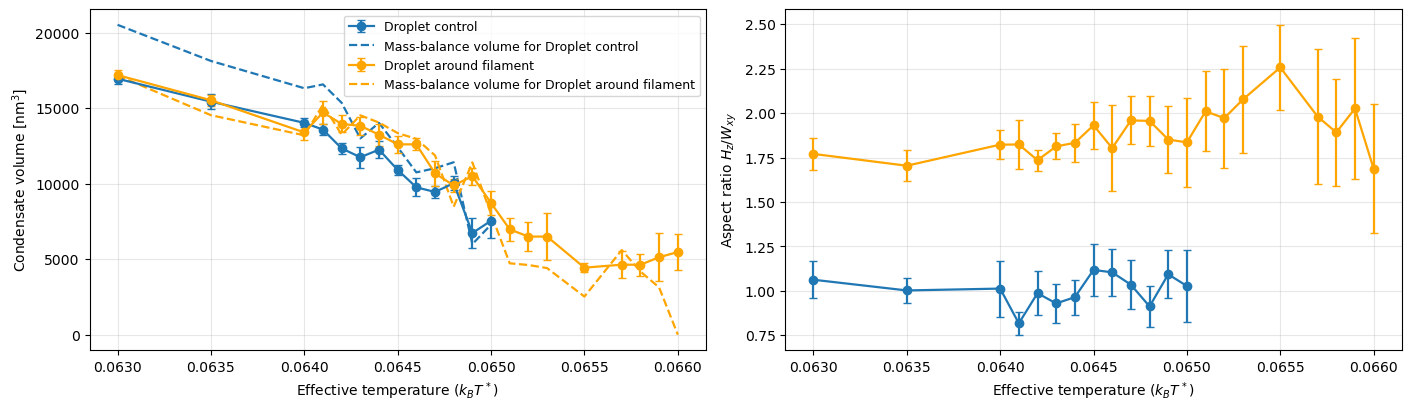

In [14]:
FOLDERS = ["Full_box/Control", "Full_box/LJ_force/LJ_0.05"]
LABELS  = ["Droplet control", r"Droplet around filament"]
COLORS = ["#1f77b4", "orange"]


fig, axes, va = plot_volume_aspect_vs_temperature(
    FOLDERS,
    labels=LABELS,
    colors=COLORS,
    runs="all",                              # "short", "long", or "all"
    min_detected_frames=3,
    use_projected_values=True,
    vol_th_legend=True,
    figsize=(14.0, 4),
    savepath="volume_aspect_vs_T.png",
)

## High_vf, volume, aspect ratio, number contacts (for polymer-droplet geometries)

In [5]:
EPSILON_PATTERN = re.compile(r"LJ[_-]?(\d+(?:\.\d+)?)", re.IGNORECASE)

def extract_epsilon(csv_path, relative_to=None):
    """
    LJ strength from a path component such as LJ_0.04.

    Searched from the deepest directory outward, so the folder holding the
    summary files wins if several components match.  Returns NaN when nothing
    matches.
    """
    path = Path(csv_path)
    if relative_to is not None:
        try:
            path = path.relative_to(relative_to)
        except ValueError:
            pass
    for part in reversed(path.parts[:-1]):          # directories only
        match = EPSILON_PATTERN.search(part)
        if match:
            return float(match.group(1))
    return np.nan


def collect_epsilon_metrics(folder, base_dir=".", skip_marker="SKIP",
                            droplet_volume="isosurface", warn_missing_epsilon=True,
                            min_detected_frames=3, use_projected_values=True,
                            rdf_method="rand_uniform_corrected", verbose=True):
    """
    Dense fraction, condensate volume and aspect ratio against LJ epsilon.

    Same file discovery as the other collectors: "Slab" in the folder name
    picks {traj}_density_summary.csv, otherwise the 3D
    {traj}_type_*_density3d_summary.csv, first species either way.  Dense
    values use dense_vf_cuboid_pol_corrected when a polymer is present.  Any
    file whose path below `folder` contains skip_marker is left out.
    """
    folder_path = Path(base_dir) / folder
    if not folder_path.is_dir():
        raise FileNotFoundError(f"No such folder: {folder_path}")

    is_slab = "slab" in str(folder).lower()
    pattern = "*_density_summary.csv" if is_slab else "*_density3d_summary.csv"
    volume_column = {
        "isosurface": "condensate_volume_isosurface_nm3",
        "cuboid": "condensate_volume_nm3",
    }[droplet_volume]

    rows = []
    for csv_path in sorted(folder_path.rglob(pattern)):
        relative = csv_path.relative_to(folder_path)
        if skip_marker and skip_marker in str(relative):
            print(f"skipped ({skip_marker} in path): {relative}")
            continue

        table = pd.read_csv(csv_path)
        if table.empty:
            continue
        row = (table.sort_values("typeid").iloc[0]
               if "typeid" in table.columns else table.iloc[0])

        # A trajectory where the condensate was never detected has fallen back
        # to averaging every frame, so its numbers describe no particular phase.
        n_detected = row.get("n_frames_detected", np.nan)
        if np.isfinite(n_detected) and n_detected < min_detected_frames:
            if verbose:
                n_total = row.get("n_frames_analysed", row.get("frames_used", "?"))
                print(f"skipped (detected in {int(n_detected)}/{n_total} frames): {csv_path.name}")
            continue

        dense = row.get("high_vf_mean", np.nan)
        dense_std = row.get("high_vf_std", np.nan)
        dilute = row.get("low_vf_mean", np.nan)
        dilute_std = row.get("low_vf_std", np.nan)
        polymer = bool(row.get("polymer_present", False))
        polymer_contact_frac = np.nan
        polymer_contact_frac_std = np.nan
        if not is_slab and polymer:
            corrected = row.get("dense_vf_cuboid_pol_corrected", np.nan)
            if np.isfinite(corrected):
                dense = corrected
                dense_std = row.get("dense_vf_cuboid_pol_corrected_std", dense_std)
            polymer_contact_frac = row.get("polymer_contact_fraction", np.nan)
            polymer_contact_frac_std = row.get("polymer_contact_fraction_std", np.nan)
            if use_projected_values:
                dense = row.get("projected_dense_vf", np.nan)
                dense_std = row.get("projected_dense_vf_std", np.nan)
                dilute = row.get("projected_dilute_vf", np.nan)
                dilute_std = row.get("projected_dilute_vf_std", np.nan)

        if is_slab:
            volume = row.get("dense_volume_nm3", np.nan)
            volume_std = row.get("dense_volume_nm3_std", np.nan)
            aspect = aspect_std = np.nan
            n_particles = n_particles_std = np.nan
        else:
            volume = row.get(volume_column, np.nan)
            volume_std = row.get(f"{volume_column}_std", np.nan)
            aspect = row.get("aspect_ratio (H_z/W_xy)", np.nan)
            aspect_std = row.get("aspect_ratio_std", np.nan)
            n_particles = row.get("isosurface_particle_count", np.nan)
            n_particles_std = row.get("isosurface_particle_count_std", np.nan)

        # Coordination number from the RDF summary of the same trajectory, written
        # next to the density summary: <trajname>_type_<id>_<name>_rdf_<method>_summary.csv
        trajname = str(row.get("trajname", csv_path.stem))
        z_in = z_in_std = np.nan
        rdf_files = sorted(csv_path.parent.glob(f"{trajname}_type_*_rdf_{rdf_method}_summary.csv"))
        rdf_files = [p for p in rdf_files if "_to_" not in p.name] or rdf_files   # prefer same-species RDF
        if rdf_files:
            rdf_row = pd.read_csv(rdf_files[0]).iloc[0]
            z_in = rdf_row.get("Z_inside", np.nan)
            z_in_std = rdf_row.get("Z_inside_frames_fixedcut_std",
                                   rdf_row.get("Z_inside_frames_std", np.nan))

        rows.append({
            "epsilon": extract_epsilon(csv_path, relative_to=folder_path),
            "trajname": str(row.get("trajname", csv_path.stem)),
            "kT": row.get("kT_kJ_per_mol", np.nan),
            "geometry": "slab" if is_slab else "droplet",
            "polymer_present": polymer,
            "high_vf": dense, "high_vf_std": dense_std,
            "volume": volume, "volume_std": volume_std,
            "n_particles": n_particles, "n_particles_std": n_particles_std,
            "aspect": aspect, "aspect_std": aspect_std,
            "contact_fraction": polymer_contact_frac,
            "contact_fraction_std": polymer_contact_frac_std,
            "Z_in": z_in, "Z_in_std": z_in_std,
            "n_frames_detected": row.get("n_frames_detected", np.nan),
            "source": str(csv_path),
        })

    if not rows:
        raise FileNotFoundError(f"No {pattern} files under {folder_path}")

    data = pd.DataFrame(rows)
    missing = data["epsilon"].isna().sum()
    if missing and warn_missing_epsilon:
        print(f"{folder}: {missing} file(s) with no LJ_<value> in their path")
    return data.sort_values("epsilon").reset_index(drop=True)


def _pool(values, stds):
    """One point and one error bar from however many trajectories share an epsilon."""
    values = np.asarray(values, dtype=float)
    stds = np.asarray(stds, dtype=float)
    good = np.isfinite(values)
    if not np.any(good):
        return np.nan, np.nan
    values, stds = values[good], stds[good]
    within = np.nanmean(stds ** 2) if np.any(np.isfinite(stds)) else 0.0
    between = np.var(values, ddof=1) if values.size > 1 else 0.0
    return float(np.mean(values)), float(np.sqrt(np.nan_to_num(within) + between))


def plot_vs_epsilon(
    folders,
    base_dir=".",
    labels=None,
    skip_marker="SKIP",
    droplet_volume="isosurface",
    connect=True,
    figsize=(12.0, 9.0),
    colors=None,
    markers=("o", "s", "^", "D", "v", "P", "X", "*"),
    log_volume=False,
    use_projected_values=True,
    rdf_method="rand_uniform_corrected",
):
    """
    Dense fraction, condensate volume and aspect ratio against LJ epsilon.

    Three stacked panels sharing the epsilon axis, one color and marker per
    folder, error bars from the frame-to-frame std.  Slab folders have no
    aspect ratio, so they simply do not appear in the third panel and are
    named in a note there instead.

    Returns (fig, axes, data) with every trajectory found, so the numbers
    behind the points stay inspectable.
    """
    if isinstance(folders, (str, Path)):
        folders = [folders]
    folders = list(folders)
    if labels is None:
        labels = [Path(f).name for f in folders]
    if colors is None:
        cycle = plt.rcParams["axes.prop_cycle"].by_key()["color"]
        colors = [cycle[i % len(cycle)] for i in range(len(folders))]

    collected = []
    for folder, label in zip(folders, labels):
        part = collect_epsilon_metrics(folder, base_dir=base_dir,
                                       skip_marker=skip_marker,
                                       droplet_volume=droplet_volume,
                                       use_projected_values=use_projected_values,
                                       rdf_method=rdf_method)
        part["folder"] = str(folder)
        part["label"] = label
        collected.append(part)
    data = pd.concat(collected, ignore_index=True)

    panels = [
        ("high_vf", "high_vf_std", "Dense volume fraction", False),
        ("volume", "volume_std", "Condensate volume [nm$^3$]", log_volume),
        ("n_particles", "n_particles_std", "Number of particles in condensate", False),
        ("Z_in", "Z_in_std", r"$N_\mathrm{coord}$", False),
        ("aspect", "aspect_std", "Aspect ratio $H_z/W_{xy}$", False),
        ("contact_fraction", "contact_fraction_std", "Polymer contact fraction", False),
    ]

    n_rows = (len(panels) + 1) // 2
    fig, grid = plt.subplots(n_rows, 2, figsize=figsize, sharex=True)
    axes = grid.T.ravel()          # column by column: left top->bottom, then right top->bottom

    for ax, (column, std_column, ylabel, log_scale) in zip(axes, panels):
        empty_labels = []
        for i, label in enumerate(labels):
            subset = data[data["label"] == label]
            points = []
            for epsilon, group in subset.groupby("epsilon", sort=True):
                value, error = _pool(group[column], group[std_column])
                if np.isfinite(value):
                    points.append((epsilon, value, error))
            if not points:
                empty_labels.append(label)
                continue

            x, y, err = (np.array(v) for v in zip(*points))
            ax.errorbar(
                x, y, yerr=err,
                marker=markers[i % len(markers)], markersize=6,
                linestyle="-" if connect else "none", linewidth=1.2,
                color=colors[i], capsize=3, label=label,
            )
            if np.any(x == 0):
                arg_0 = np.where(x == 0)[0]
                ax.errorbar(x[arg_0], y[arg_0], yerr=err[arg_0], marker=markers[0], markersize=6,
                           linestyle="none", color="red", capsize=3, label="Droplet control")

        if empty_labels:
            ax.text(0.98, 0.06, "no data: " + ", ".join(empty_labels),
                    transform=ax.transAxes, ha="right", va="bottom",
                    fontsize=8, color="grey", style="italic")

        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)
        if log_scale:
            ax.set_yscale("log")

    axes[0].legend(fontsize=9)
    for ax in grid[-1, :]:
        ax.set_xlabel(r"LJ strength $\epsilon_{prot-fil, attr}$")
    fig.tight_layout()

    return fig, axes, data


def plot_contact_fraction_vs_temperature(
    folders,
    labels=None,
    colors=None,
    base_dir=".",
    epsilon=None,
    max_temp=None,
    skip_marker="SKIP",
    use_projected_values=True,
    connect=True,
    markers=("o", "s", "^", "D", "v", "P", "X", "*"),
    ax=None,
    figsize=(7.0, 4.5),
    savepath=None,
    dpi=300,
):
    """
    Polymer contact fraction against temperature, one colour and marker per
    folder, with the frame-to-frame std as error bars.

    Values come from collect_epsilon_metrics.  Trajectories at the same
    temperature are combined with _pool.  epsilon=<value> keeps only runs at that
    LJ strength (use it when a folder holds several); max_temp drops higher
    temperatures (inclusive).
    Returns (fig, ax, data) with every trajectory used.
    """
    if isinstance(folders, (str, Path)):
        folders = [folders]
    folders = list(folders)
    if labels is None:
        labels = [Path(f).name for f in folders]
    if colors is None:
        cycle = plt.rcParams["axes.prop_cycle"].by_key()["color"]
        colors = [cycle[i % len(cycle)] for i in range(len(folders))]

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize, layout="constrained")
    else:
        fig = ax.figure

    collected = []
    for i, (folder, label) in enumerate(zip(folders, labels)):
        part = collect_epsilon_metrics(folder, base_dir=base_dir, skip_marker=skip_marker,
                                       warn_missing_epsilon=False,
                                       use_projected_values=use_projected_values)
        part["kT"] = pd.to_numeric(part["kT"], errors="coerce")
        part = part[np.isfinite(part["kT"])]
        if epsilon is not None:
            part = part[np.isclose(part["epsilon"], epsilon)]
        if max_temp is not None:
            part = part[part["kT"] <= max_temp]
        part = part.assign(folder=str(folder), label=label)
        collected.append(part)

        points = []
        for temp, group in part.groupby("kT", sort=True):
            value, error = _pool(group["contact_fraction"], group["contact_fraction_std"])
            if np.isfinite(value):
                points.append((temp, value, error if np.isfinite(error) else 0.0))
        if not points:
            print(f"{label}: no contact fractions (no polymer, slab folder, or nothing detected)")
            continue

        x, y, err = (np.array(v) for v in zip(*points))
        ax.errorbar(x, y, yerr=err, marker=markers[i % len(markers)], markersize=6,
                    linestyle="-" if connect else "none", linewidth=1.4,
                    color=colors[i], capsize=3, label=label)

    ax.set_xlabel(r"Effective temperature ($k_BT^*$)")
    ax.set_ylabel("Polymer contact fraction")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)

    if savepath is not None:
        fig.savefig(savepath, dpi=dpi, bbox_inches="tight")
    return fig, ax, pd.concat(collected, ignore_index=True)

### Temp 0.064 vs polymer to side

skipped (SKIP in path): LJ_0.05\SKIP_test\elongation_kT_0.064_traj_lj0.05_type_2_3PPB_core_density3d_summary.csv


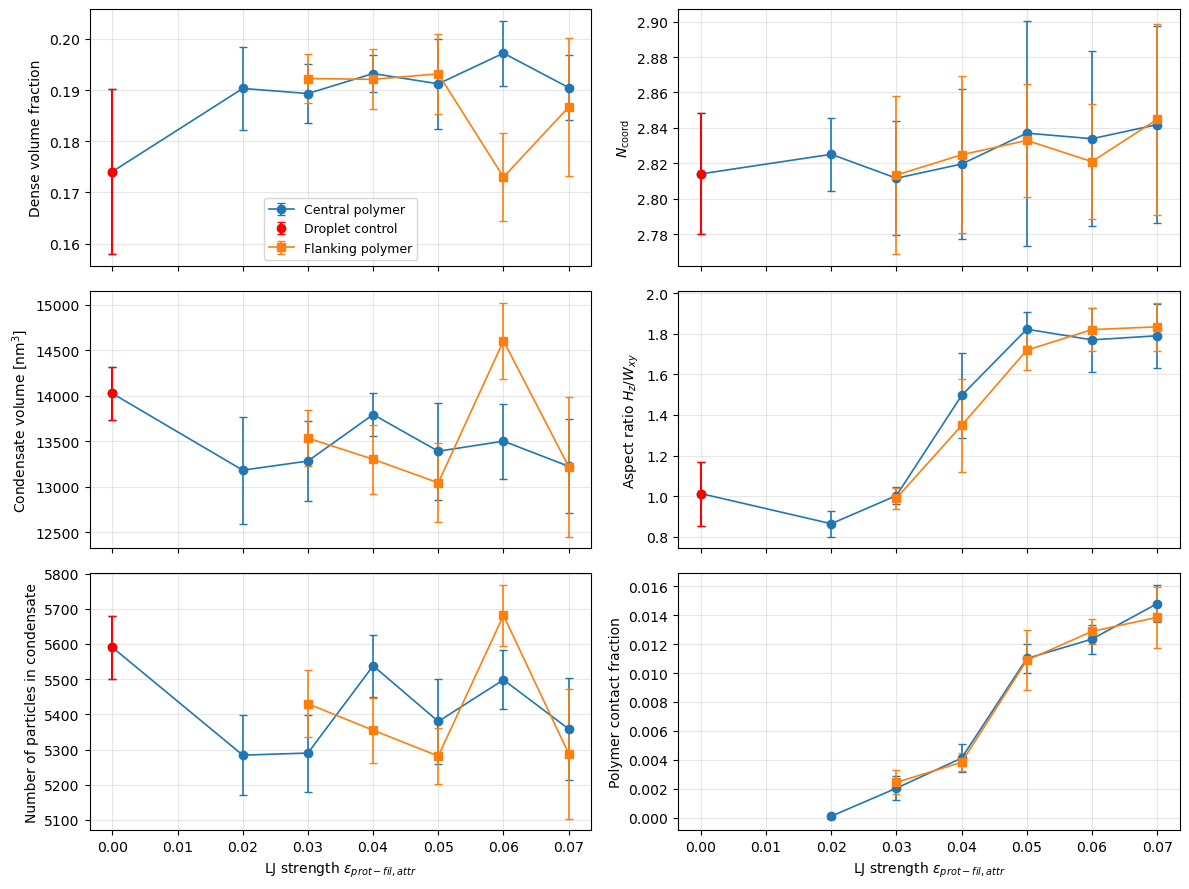

In [6]:
FOLDERS = ["Full_box/LJ_force/Temp_0.064", "Full_box/Polymer_to_side"]
LABELS  = ["Central polymer", "Flanking polymer"]

fig, axes, data = plot_vs_epsilon(FOLDERS, labels=LABELS, use_projected_values=True)
data[["label", "epsilon", "high_vf", "volume", "aspect"]]
fig.savefig("polymer_to_side.png", dpi=300, bbox_inches="tight")

### For temp very close to critical temp, temp=0.066: control, lj0.06, lj0.1, lj0.6

skipped (SKIP in path): LJ_0.06\Test_pol_corr_SKIP\elongation_kT_0.066_traj_lj0.06_type_2_3PPB_core_density3d_summary.csv
skipped (SKIP in path): LJ_0.60\Test_pol_corr_SKIP\elongation_kT_0.066_traj_type_2_3PPB_core_density3d_summary.csv


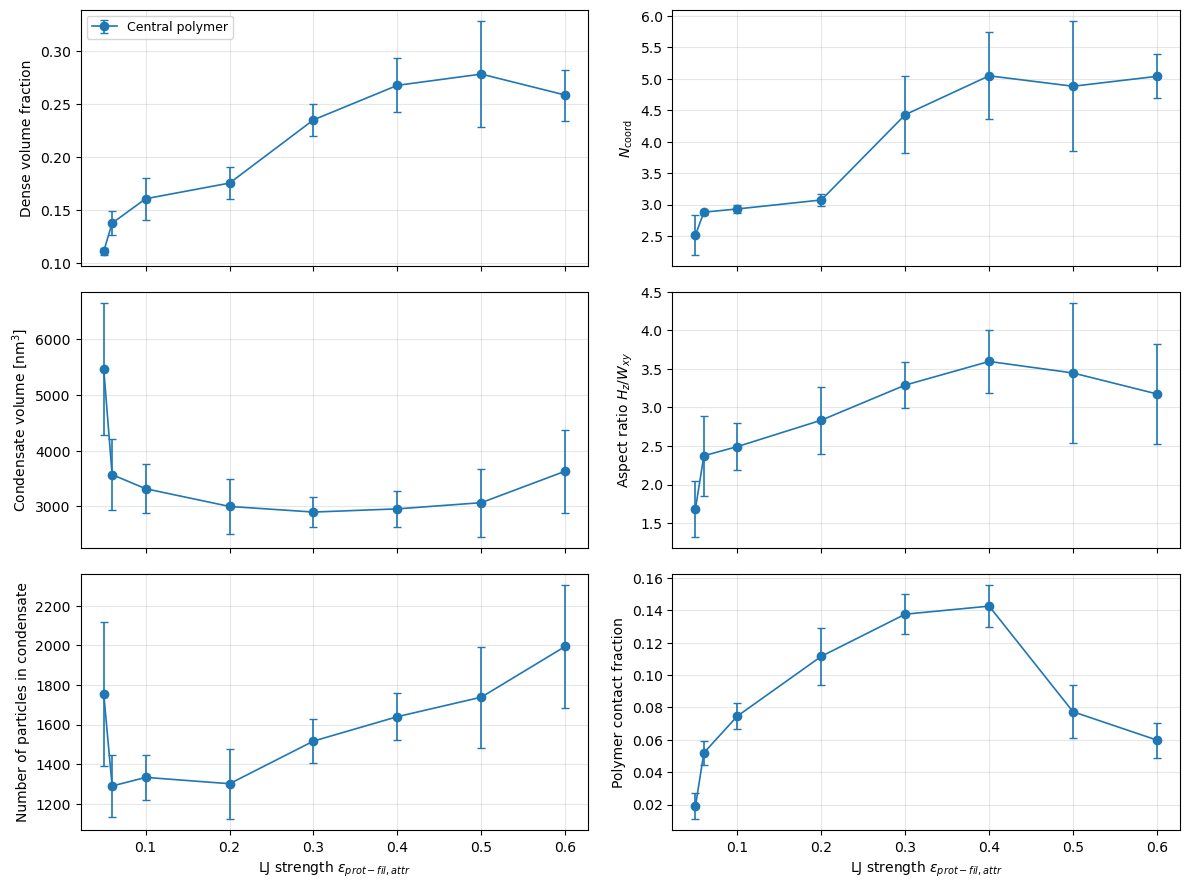

In [7]:
FOLDERS = ["Full_box/LJ_force/Temp_0.066"]
LABELS  = ["Central polymer"]

fig, axes, data = plot_vs_epsilon(FOLDERS, labels=LABELS, use_projected_values=True)
data[["label", "epsilon", "high_vf", "volume", "aspect"]]
fig.savefig("Close_to_crit_temp_fullbox.png", dpi=300, bbox_inches="tight")

### Contact fraction vs temperature (LJ=0.05)

skipped (SKIP in path): 0.063_OLD_SKIP\elongation_kT_0.063_traj_type_2_3PPB_core_density3d_summary.csv
skipped (SKIP in path): 0.06495_TODO_SKIP\elongation_kT_0.06495_traj_type_2_3PPB_core_density3d_summary.csv
skipped (SKIP in path): 0.064_differentPolyCount_SKIP\elongation_kT_0.064_traj_lj0.05_type_2_3PPB_core_density3d_summary.csv
skipped (SKIP in path): 0.06515_TODO_SKIP\elongation_kT_0.06515_traj_type_2_3PPB_core_density3d_summary.csv
skipped (SKIP in path): 0.065_short_SKIP\elongation_kT_0.065_traj_short_type_2_3PPB_core_density3d_summary.csv
skipped (detected in 0/10 frames): elongation_kT_0.07_traj_type_2_3PPB_core_density3d_summary.csv
skipped (detected in 0/10 frames): elongation_kT_0.075_traj_type_2_3PPB_core_density3d_summary.csv
skipped (detected in 0/10 frames): elongation_kT_0.08_traj_type_2_3PPB_core_density3d_summary.csv
skipped (detected in 0/10 frames): elongation_kT_0.085_traj_type_2_3PPB_core_density3d_summary.csv
skipped (detected in 0/10 frames): elongation_kT_0.

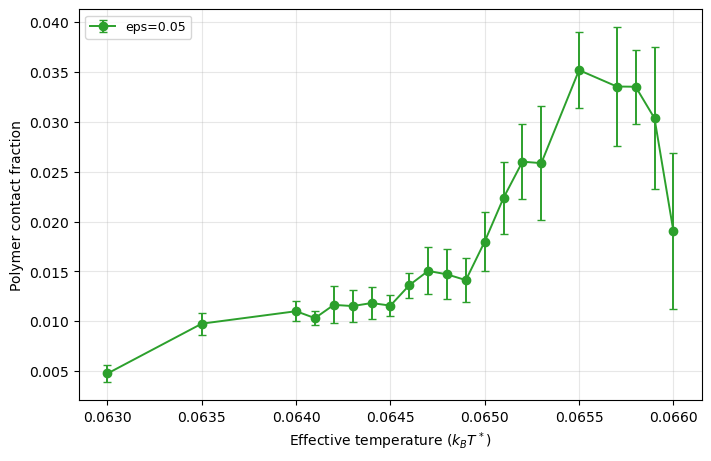

In [12]:
FOLDERS = ["Full_box/LJ_force/LJ_0.05"]
LABELS  = ["eps=0.05"]

fig, ax, cf = plot_contact_fraction_vs_temperature(
    FOLDERS,
    labels=LABELS,
    colors=["tab:green"],
    savepath=None,
)

## Polymer spacing at kbT=0.064

In [15]:
"""
Condensate properties against filament spacing.

Reads the reference species' *_density3d_summary.csv in every "<spacing>_nm"
folder under a parent directory and plots volume, aspect ratio, total polymer
contacts and deltaG_transfer/kT = -ln(phi_dense/phi_dilute) against spacing.
"""

SPACING_RE = re.compile(r"^([-+]?\d*\.?\d+)_nm$")
PHI_DENSE_INF = 0.196926935825624                 # Value from control slab at kbT=0.064
PHI_DILUTE_INF = 0.00967915053539655              # Value from control slab at kbT=0.064
PLAIN_POLYMER_POTENTIAL = 7.094152                # Value from single polymer run at kbT=0.064
MAX_POL_BEAD_DISPLACEMENT = 1.89087787828413      # Value from single polymer run at kbT=0.064
MAX_POL_COM_DISPLACEMENT = 1.0542597255574        # Value from single polymer run at kbT=0.064


def _num(row, key):
    value = pd.to_numeric(pd.Series([row.get(key, np.nan)]), errors="coerce").iloc[0]
    return float(value) if pd.notna(value) else np.nan


def _summary_row(folder, skip_keyword="SKIP", kT=None):
    """Reference-species row of every *_density3d_summary.csv in folder (subfolders too)."""
    rows = []
    for path in sorted(Path(folder).rglob("*_density3d_summary.csv")):
        if skip_keyword and skip_keyword in str(path.relative_to(folder)):
            continue
        table = pd.read_csv(path)
        if table.empty:
            continue
        row = table.sort_values("typeid").iloc[0] if "typeid" in table.columns else table.iloc[0]
        if kT is not None and not np.isclose(_num(row, "kT_kJ_per_mol"), kT):
            continue
        rows.append((path, row))
    return rows


def _final_potential_energy(summary_path, trajname, n_last=10):
    """Mean and std of potential_energy over the last n_last rows of the run's *_observables.csv."""
    obs_path = Path(summary_path).with_name(f"{trajname}_observables.csv")
    if not obs_path.exists():
        return np.nan, np.nan
    obs = pd.read_csv(obs_path)
    if "potential_energy" not in obs.columns:
        return np.nan, np.nan
    if "step" in obs.columns:
        obs = obs.sort_values("step")
    energy = pd.to_numeric(obs["potential_energy"], errors="coerce").dropna().to_numpy()[-int(n_last):]
    if energy.size == 0:
        return np.nan, np.nan
    return float(energy.mean()), float(energy.std(ddof=1)) if energy.size > 1 else np.nan


def _polymer_force_quantity(summary_path, trajname, quantity="com_separation", max_up=2):
    """
    Mean and std of one quantity from droplet_polymer_force.csv for this run.

    Looks next to the summary file and up to max_up folders above it (in case the
    analysis output sits in a subfolder of the run folder), preferring a
    run-specific <trajname>_droplet_polymer_force.csv over the generic name.
    """
    folder = Path(summary_path).parent
    for _ in range(max_up + 1):
        # Make special case when there is only one polymer (0 nm)
        if "0nm" in folder.name:
            name = f"{trajname}_polymer_displacement_summary.csv"
            candidate = folder / name
            if candidate.exists():
                table = pd.read_csv(candidate)
                row = table.sort_values("typeid").iloc[0] if "typeid" in table.columns else table.iloc[0]
                return (-1 * _num(row, "com_r_mean_nm"), _num(row, "com_r_std_nm"))
            continue
        for name in (f"{trajname}_droplet_polymer_force.csv", "droplet_polymer_force.csv"):
            candidate = folder / name
            if candidate.exists():
                table = pd.read_csv(candidate).set_index("quantity")
                if quantity not in table.index:
                    return np.nan, np.nan
                return (_num(table.loc[quantity], "mean"), _num(table.loc[quantity], "std"))
        folder = folder.parent
    return np.nan, np.nan


def collect_spacing_metrics(parent_dir, use_projected_values=False, skip_keyword="SKIP", kT=None,
                            sigma=1.0, n_last_energy=10, rdf_method="rand_uniform_corrected"):
    """
    One row per "<spacing>_nm" folder (and per summary file inside it).

    Columns: spacing_nm, kT, dense, dense_std, dilute, dilute_std, volume,
    volume_std, aspect, aspect_std, n_polymer_chains, contacts_total,
    contacts_total_std, plus per chain contacts_k, contacts_k_std,
    beads_in_k, beads_in_k_std, and deltaG_kT, deltaG_kT_std.

    use_projected_values: dense/dilute from projected_dense_vf/projected_dilute_vf
    instead of high_vf/low_vf.  kT: keep only runs at this temperature.
    """
    dense_key, dilute_key = (("projected_dense_vf", "projected_dilute_vf") if use_projected_values
                             else ("high_vf", "low_vf"))
    records = []
    for folder in sorted(Path(parent_dir).iterdir()):
        match = SPACING_RE.match(folder.name)
        if not folder.is_dir() or not match:
            continue
        if skip_keyword and skip_keyword in folder.name:
            continue
        spacing = float(match.group(1))
        for path, row in _summary_row(folder, skip_keyword, kT):
            rec = {
                "spacing_nm": spacing,
                "kT": _num(row, "kT_kJ_per_mol"),
                "dense": _num(row, dense_key), "dense_std": _num(row, f"{dense_key}_std"),
                "dilute": _num(row, dilute_key), "dilute_std": _num(row, f"{dilute_key}_std"),
                "volume": _num(row, "condensate_volume_isosurface_nm3"),
                "volume_std": _num(row, "condensate_volume_isosurface_nm3_std"),
                "aspect": _num(row, "aspect_ratio (H_z/W_xy)"),
                "aspect_std": _num(row, "aspect_ratio_std"),
                "source": str(path),
            }
            n_chains = _num(row, "n_polymer_chains")
            n_chains = int(n_chains) if np.isfinite(n_chains) else 1
            rec["n_polymer_chains"] = n_chains

            if n_chains > 1:
                # per-chain columns polymer1_*, polymer2_*, ...
                for k in range(1, n_chains + 1):
                    if spacing == 29.0:
                        ### ADDED A SPECIAL COMMAND BECAUSE HERE I KNOW THE FIRST POLYMER AT SPACING 29 SHOULD HAVE 0 EVERYWHERE
                        ### TODO: HAVE TO PERFECT analysis_last.py TO AVOID THIS
                        if k == 1:
                            print(f"Skipped polymer {k} for spacing {spacing}.")
                            rec[f"contacts_{k}"] = 0
                            rec[f"contacts_{k}_std"] = 0
                            rec[f"beads_in_{k}"] = 0
                            rec[f"beads_in_{k}_std"] = 0
                            continue
                    rec[f"contacts_{k}"] = _num(row, f"polymer{k}_n_contacts")
                    rec[f"contacts_{k}_std"] = _num(row, f"polymer{k}_n_contacts_std")
                    rec[f"beads_in_{k}"] = _num(row, f"polymer{k}_n_core_beads_in")
                    rec[f"beads_in_{k}_std"] = _num(row, f"polymer{k}_n_core_beads_in_std")                    
            else:
                # one chain: the combined polymer_* columns are that chain
                rec["contacts_1"] = _num(row, "polymer_n_contacts")
                rec["contacts_1_std"] = _num(row, "polymer_n_contacts_std")
                rec["beads_in_1"] = _num(row, "polymer_n_core_beads_in")
                rec["beads_in_1_std"] = _num(row, "polymer_n_core_beads_in_std")

            contacts = np.array([rec[f"contacts_{k}"] for k in range(1, n_chains + 1)])
            stds = np.array([rec[f"contacts_{k}_std"] for k in range(1, n_chains + 1)])
            rec["contacts_total"] = float(np.sum(contacts)) if np.all(np.isfinite(contacts)) else np.nan
            rec["contacts_total_std"] = (float(np.sqrt(np.sum(stds ** 2)))
                                         if np.all(np.isfinite(stds)) else np.nan)

            d, l = rec["dense"], rec["dilute"]
            if np.isfinite(d) and np.isfinite(l) and d > 0 and l > 0:
                rec["deltaG_kT"] = -np.log(d / l)
                rel = [s / v for s, v in ((rec["dense_std"], d), (rec["dilute_std"], l)) if np.isfinite(s)]
                rec["deltaG_kT_std"] = float(np.sqrt(np.sum(np.square(rel)))) if rel else np.nan
            else:
                rec["deltaG_kT"] = rec["deltaG_kT_std"] = np.nan
                
            # Surface tension from the Gibbs-Thomson shift of the dilute phase:
            # gamma/kT = phi_dense_inf * R / (2 v_p) * ln(phi_dilute / phi_dilute_inf)
            R = _num(row, "condensate_radius_equiv_nm")
            R_std = _num(row, "condensate_radius_equiv_nm_std")
            rec["radius_nm"], rec["radius_nm_std"] = R, R_std
            vol_particle = 1.0 / 6.0 * np.pi * sigma ** 3
            A = PHI_DENSE_INF / (2.0 * vol_particle)
            if np.isfinite(R) and np.isfinite(l) and l > 0:
                log_ratio = np.log(l / PHI_DILUTE_INF)
                rec["gamma_kT"] = A * R * log_ratio
                terms = []
                if np.isfinite(R_std):
                    terms.append(A * log_ratio * R_std)            # d gamma / d R
                if np.isfinite(rec["dilute_std"]):
                    terms.append(A * R * rec["dilute_std"] / l)    # d gamma / d phi_dilute
                rec["gamma_kT_std"] = float(np.sqrt(np.sum(np.square(terms)))) if terms else np.nan
            else:
                rec["gamma_kT"] = rec["gamma_kT_std"] = np.nan

            # Final potential energy minus that of the bare polymer chains.
            u_plain = PLAIN_POLYMER_POTENTIAL
            trajname = str(row.get("trajname", path.name.split("_type_")[0]))
            e_mean, e_std = _final_potential_energy(path, trajname, n_last_energy)
            rec["potential_energy"], rec["potential_energy_std"] = e_mean, e_std
            rec["potential_energy_excess"] = e_mean - n_chains * u_plain
            rec["potential_energy_excess_std"] = e_std

            # Coordination number from this run's RDF summary, next to the density summary.
            z_in = z_in_std = np.nan
            rdf_files = sorted(Path(path).parent.glob(f"{trajname}_type_*_rdf_{rdf_method}_summary.csv"))
            rdf_files = [p for p in rdf_files if "_to_" not in p.name] or rdf_files   # prefer same-species RDF
            if rdf_files:
                rdf_row = pd.read_csv(rdf_files[0]).iloc[0]
                z_in = _num(rdf_row, "Z_inside")
                z_in_std = _num(rdf_row, "Z_inside_frames_fixedcut_std")
                if not np.isfinite(z_in_std):
                    z_in_std = _num(rdf_row, "Z_inside_frames_std")
            rec["Z_in"], rec["Z_in_std"] = z_in, z_in_std

            # Actual distance between polymers' center of mass
            com_d, com_d_std = _polymer_force_quantity(path, trajname, "com_separation")
            relative_com_d = rec["spacing_nm"] - com_d
            rec["com_separation"] = com_d
            rec["relative_com_sep_nm"], rec["com_separation_nm_std"] = relative_com_d, com_d_std
            
            records.append(rec)

    if not records:
        raise FileNotFoundError(f"No '<spacing>_nm' folders with *_density3d_summary.csv under {parent_dir}")
    return pd.DataFrame(records).sort_values("spacing_nm").reset_index(drop=True)


def plot_spacing_series(
    parent_dir,
    use_projected_values=False,
    kT=None,
    sigma=1.0,
    n_last_energy=10,
    rdf_method="rand_uniform_corrected",
    color="tab:blue",
    label=None,
    axes=None,
    shade_range=None,          # (x_min, x_max) in nm, or None for no shading
    shade_color="magenta",
    shade_alpha=0.15,
    figsize=(7.0, 14.0),       # increase height by 3.5 for each panel
    markersize=6,
    linewidth=1.6,
    capsize=3,
    skip_keyword="SKIP",
    savepath=None,
    dpi=300,
):
    """
    Four stacked panels against filament spacing (nm): isosurface volume,
    aspect ratio H_z/W_xy, total polymer contacts (summed over chains), and
    deltaG_transfer/kT = -ln(phi_dense/phi_dilute), all with error bars.

    Pass the axes returned by an earlier call (axes=...) with another colour
    and label to overlay a second parent directory.
    Returns (fig, axes, data).
    """
    data = collect_spacing_metrics(parent_dir, use_projected_values, skip_keyword, kT,
                                   sigma=sigma, n_last_energy=n_last_energy,
                                   rdf_method=rdf_method)
    # several runs at one spacing: average them, std of the per-run stds combined
    grouped = data.groupby("spacing_nm")

    panels = (
        ("volume", "volume_std", "Condensate volume [nm$^3$]"),
        ("aspect", "aspect_std", "Aspect ratio $H_z/W_{xy}$"),
        ("contacts_total", "contacts_total_std", "Patchy particle–filament\ncontacts"),
        # ("Z_in", "Z_in_std", r"$N_\mathrm{coord}$"),
        ("relative_com_sep_nm", "com_separation_nm_std", "Total displacement of\npolymer centres of mass [nm]"),
        # ("com_separation", "com_separation_nm_std", "Polymers centre \nof mass distance (r) [nm]"),
        # ("potential_energy_excess", "potential_energy_excess_std", "Potential energy [kJ/mol]"),
        ("deltaG_kT", "deltaG_kT_std", r"$\Delta G_\mathrm{transfer}/k_BT$"),
        ("gamma_kT", "gamma_kT_std", r"$\gamma/k_BT$ [nm$^{-2}$]"),
    )
    if axes is None:
        fig, axes = plt.subplots(len(panels), 1, figsize=figsize, sharex=True, layout="constrained")
    else:
        fig = axes[0].figure

    for ax, (column, std_column, ylabel) in zip(axes, panels):
        x = np.array(list(grouped.groups.keys()), dtype=float)
        y = grouped[column].mean().to_numpy(dtype=float)
        err = np.sqrt(grouped[std_column].apply(lambda s: np.nanmean(np.square(s))
                                                if s.notna().any() else np.nan)).to_numpy(dtype=float)
        ok = np.isfinite(y)
        ax.errorbar(x[ok], y[ok], yerr=np.where(np.isfinite(err[ok]), err[ok], 0.0),
                    marker="o", markersize=markersize, linewidth=linewidth, capsize=capsize,
                    color=color, label=label)
        if "displacement" in ylabel:
            # main_diagonal = np.linspace(x[0], x[-1] + 1, 1000)
            # ax.plot(main_diagonal, main_diagonal, color="black", linestyle="dashed",
            #        linewidth=2.0, label=r"$\mathrm{x=y}$")
            ax.hlines(y=2*MAX_POL_COM_DISPLACEMENT, xmin=shade_range[0], xmax=shade_range[1],
                      color="black", linestyle="dashed", linewidth=2.0, label=r"Maximum attractive displacement")
            ax.legend(fontsize=9, loc="center right")
        if "of mass distance" in ylabel:
            main_diagonal = np.linspace(x[0], x[-1] + 1, 1000)
            ax.plot(main_diagonal, main_diagonal, color="black", linestyle="dashed",
                   linewidth=2.0, label=r"$\mathrm{x=y}$")
            ax.legend(fontsize=9, loc="center right")
        if shade_range is not None:
            ax.axvspan(*shade_range, color=shade_color, alpha=shade_alpha, lw=0, zorder=0)
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)
    axes[-1].set_xlabel("Filament spacing [nm]")
    if label is not None:
        axes[0].legend(fontsize=9)

    if savepath is not None:
        fig.savefig(savepath, dpi=dpi, bbox_inches="tight")
    return fig, axes, data


Skipped polymer 1 for spacing 29.0.


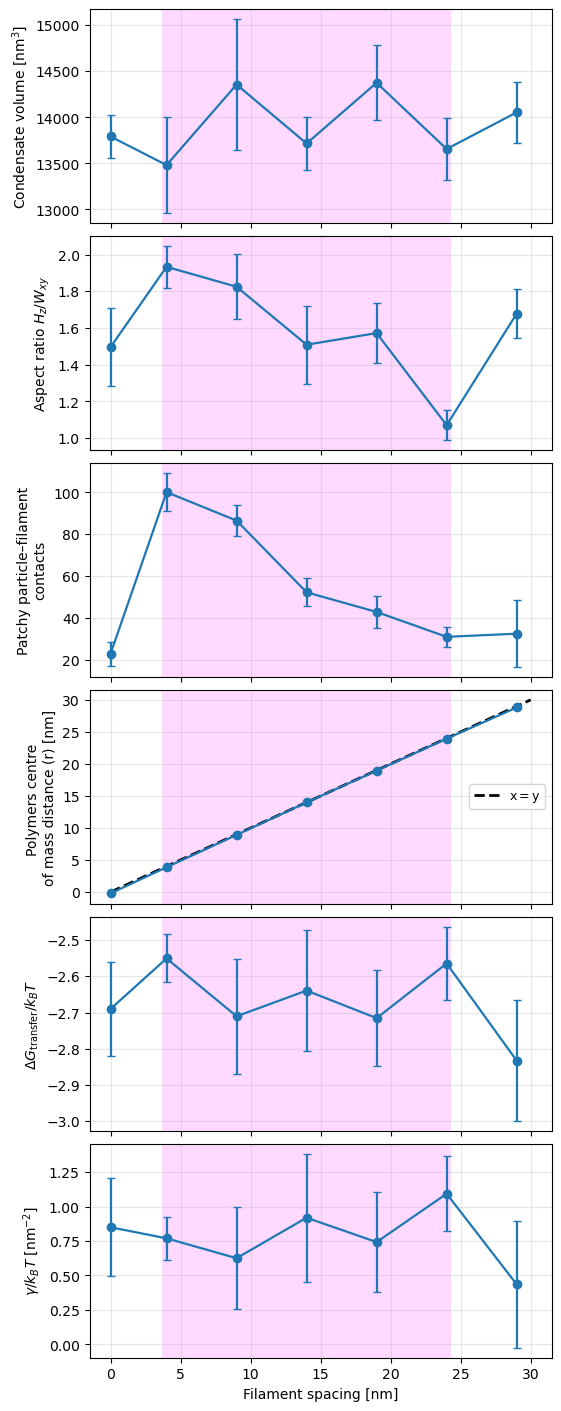

In [16]:
FOLDER = "Full_box/Polymers_parallel"
LABEL  = None    #    "Central polymer"


fig, axes, data = plot_spacing_series(
    FOLDER,                          # parent directory with the "<dist>_nm" folders
    use_projected_values=True,       # True: projected_dense_vf / projected_dilute_vf
    sigma=1.0,
    label=LABEL,
    shade_range=(3.7, 24.3),
    figsize=(5.5, 14.0),            # increase height by 3.5 for each panel
    savepath="par_pol.png",
)

## Volume vs temp for controls

In [22]:
def plot_volume_vs_temperature(
    folders,
    base_dir=".",
    labels=None,
    skip_marker="SKIP",
    droplet_volume="isosurface",
    min_detected_frames=4,
    connect=True,
    figsize=(7.0, 5.0),
    colors=None,
    markers=("o", "s", "^", "D", "v", "P", "X", "*"),
    log_volume=False,
    ax=None,
    use_projected_values=True,
    crit_temp=None,
):
    """
    Condensate volume against temperature, one color per folder.

    The volume is the isosurface volume for droplet folders and
    dense_volume_nm3 for slab folders, which collect_epsilon_metrics already
    selects by geometry.  Trajectories sharing a temperature within a folder
    are pooled, the error bar combining their frame-to-frame std with the
    spread between them.

    Returns (fig, ax, data).
    """
    if isinstance(folders, (str, Path)):
        folders = [folders]
    folders = list(folders)
    if labels is None:
        labels = [Path(f).name for f in folders]
    if colors is None:
        cycle = plt.rcParams["axes.prop_cycle"].by_key()["color"]
        colors = [cycle[i % len(cycle)] for i in range(len(folders))]

    collected = []
    for folder, label in zip(folders, labels):
        part = collect_epsilon_metrics(folder, base_dir=base_dir,
                                       skip_marker=skip_marker,
                                       droplet_volume=droplet_volume,
                                       warn_missing_epsilon=False,
                                       min_detected_frames=min_detected_frames,
                                       use_projected_values=use_projected_values)
        part["folder"] = str(folder)
        part["label"] = label
        collected.append(part)
    data = pd.concat(collected, ignore_index=True)

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    for i, label in enumerate(labels):
        subset = data[data["label"] == label]
        points = []
        for kT, group in subset.groupby("kT", sort=True):
            value, error = _pool(group["volume"], group["volume_std"])
            if np.isfinite(value):
                points.append((kT, value, error))
        if not points:
            print(f"{label}: no volumes to plot")
            continue

        x, y, err = (np.array(v) for v in zip(*points))
        geometry = subset["geometry"].iloc[0]

        if crit_temp is not None:
            x = x / crit_temp[i]
        
        ax.errorbar(
            x, y, yerr=err,
            marker=markers[i % len(markers)], markersize=6,
            linestyle="-" if connect else "none", linewidth=1.2,
            color=colors[i], capsize=3,
            label=f"{label}",
        )

    if crit_temp is not None:
        ax.set_xlabel(r"Normalized $T_{norm} = T/T_c$")
    else:
        ax.set_xlabel(r"Effective $k_BT^*$")
    ax.set_ylabel("Condensate volume [nm$^3$]")
    if log_volume:
        ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)
    fig.tight_layout()

    return fig, ax, data

skipped (SKIP in path): 0.067_README_SKIP\elongation_kT_0.067_traj_density_summary.csv
skipped (SKIP in path): 0.065_short_SKIP\elongation_kT_0.065_traj_type_2_3PPB_core_density3d_summary.csv


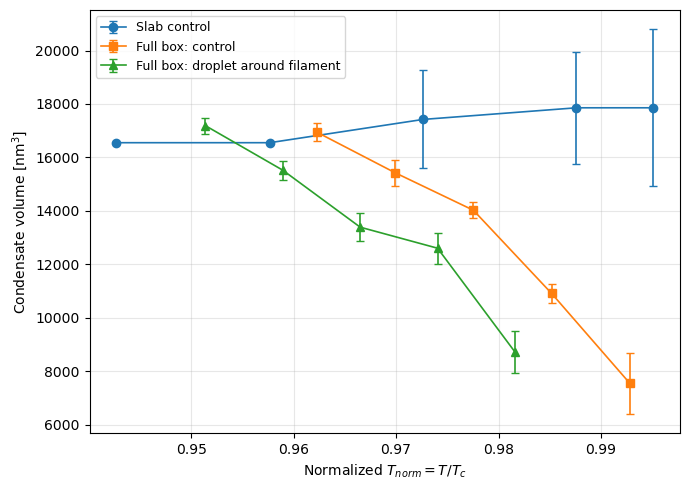

In [24]:
# Critical temperatures from phase diagrams:
# 0.066828872536696    (slab)
# 0.06547048550893132  (full_box)
# 0.06621857150684841  (full_box with filament, lj=0.05)

FOLDERS = ["Slab/Control", "Full_box/Volume_geom_effect/Control", "Full_box/Volume_geom_effect/LJ_0.05"]
CRIT_TEMP = [0.066828872536696, 0.06547048550893132, 0.06621857150684841]



fig, ax, data = plot_volume_vs_temperature(
    FOLDERS,
    labels=["Slab control", "Full box: control", r"Full box: droplet around filament"],
    min_detected_frames=3,
    use_projected_values=True,
    crit_temp = CRIT_TEMP    # or None
)
fig.savefig("volume_trend.png", dpi=300, bbox_inches="tight")

## MSD and RDF comparisons

In [25]:
"""
MSD and RDF comparison across folders and temperatures.

Column 1: MSD vs time (log-log) per folder, with a 6Dt fit on the late-time
tail of every curve; last row: D vs temperature for all folders.
Column 2: inside g(r) per folder; last row: Z_inside vs temperature.
Reads the CSVs written by analysis_last.py.
"""

TEMP_LABEL = r"Effective temperature ($k_BT^*$)"


def _find(folder, pattern, skip_keyword="SKIP", contains=None):
    """Files matching pattern under folder (subfolders too), minus skipped ones."""
    folder = Path(folder)
    out = []
    for path in sorted(folder.rglob(pattern)):
        rel = str(path.relative_to(folder))
        if skip_keyword and skip_keyword in rel:
            continue
        if contains and contains not in path.name:
            continue
        out.append(path)
    return out


def _temperature(df, path, suffix):
    """kT from the kT_kJ_per_mol column, else the 2nd-to-last '_' item of the trajname."""
    if "kT_kJ_per_mol" in df.columns:
        kT = pd.to_numeric(df["kT_kJ_per_mol"], errors="coerce").dropna()
        if len(kT):
            return float(kT.iloc[0])
    if "trajname" in df.columns and len(df):
        name = str(df["trajname"].iloc[0])
    else:
        name = path.name.split(suffix)[0]
    parts = name.split("_")
    try:
        return float(parts[-2])
    except (IndexError, ValueError):
        return np.nan


def fit_msd_tail(t, msd, tail_fraction=0.3):
    """
    Least-squares fit of MSD = 6 D t through the origin on the last
    tail_fraction of the (positive, time-sorted) points.
    Returns (D, t_fit, msd_fit) with the fitted line on the fit range.
    """
    good = np.isfinite(t) & np.isfinite(msd) & (t > 0) & (msd > 0)
    t, msd = t[good], msd[good]
    order = np.argsort(t)
    t, msd = t[order], msd[order]
    n_fit = max(2, int(np.ceil(tail_fraction * t.size)))
    if t.size < 2:
        return np.nan, np.array([]), np.array([])
    tt, mm = t[-n_fit:], msd[-n_fit:]
    D = float(np.sum(tt * mm) / (6.0 * np.sum(tt * tt)))
    return D, tt, 6.0 * D * tt


def load_msd_runs(folder, skip_keyword="SKIP", msd_contains=None, tail_fraction=0.3):
    """Every *_msd.csv under folder: list of dicts (kT, t, msd, D, t_fit, msd_fit), sorted by kT."""
    runs = []
    for path in _find(folder, "*_msd.csv", skip_keyword, msd_contains):
        df = pd.read_csv(path)
        kT = _temperature(df, path, "_species_")
        if not np.isfinite(kT):
            print(f"Skipping {path}: no temperature found")
            continue
        t = pd.to_numeric(df["time_ps"], errors="coerce").to_numpy(dtype=float)
        msd = pd.to_numeric(df["msd_nm2"], errors="coerce").to_numpy(dtype=float)
        D, t_fit, msd_fit = fit_msd_tail(t, msd, tail_fraction)
        runs.append(dict(kT=kT, t=t, msd=msd, D=D, t_fit=t_fit, msd_fit=msd_fit, path=path))
    return sorted(runs, key=lambda r: r["kT"])


def load_rdf_runs(folder, method="rand_uniform_corrected", skip_keyword="SKIP", rdf_contains=None):
    """Every *_rdf_<method>.csv under folder with its summary: list of dicts (kT, r, g, Z), sorted by kT."""
    runs = []
    for path in _find(folder, f"*_rdf_{method}.csv", skip_keyword, rdf_contains):
        df = pd.read_csv(path)
        kT = _temperature(df, path, "_type_")
        if not np.isfinite(kT):
            print(f"Skipping {path}: no temperature found")
            continue
        summary_path = path.with_name(path.name.replace(".csv", "_summary.csv"))
        Z = np.nan
        if summary_path.exists():
            summary = pd.read_csv(summary_path)
            if "Z_inside" in summary.columns and len(summary):
                Z = float(summary["Z_inside"].iloc[0])
        r = pd.to_numeric(df["r_nm"], errors="coerce").to_numpy(dtype=float)
        g = pd.to_numeric(df["inside"], errors="coerce").to_numpy(dtype=float)
        runs.append(dict(kT=kT, r=r, g=g, Z=Z, path=path))
    return sorted(runs, key=lambda r: r["kT"])


def _corner_label(ax, text, corner="left"):
    x, ha = (0.03, "left") if corner == "left" else (0.97, "right")
    ax.text(x, 0.95, text, transform=ax.transAxes, ha=ha, va="top", fontsize=9,
            bbox=dict(boxstyle="round", facecolor="white", edgecolor="0.6", alpha=0.9))


def plot_msd_rdf_comparison(
    folders,
    labels,
    folder_colors=None,
    cmap="coolwarm",
    crit_temps=None,
    rdf_method="rand_uniform_corrected",
    msd_tail_fraction=0.4,
    rdf_vlines=(1.0, np.sqrt(3.0), np.sqrt(7.0)),
    msd_contains=None,
    rdf_contains=None,
    skip_keyword="SKIP",
    figsize=None,
    linewidth=1.2,
    last_xticks=None,
    savepath=None,
    dpi=300,
):
    """
    2 columns x (n+1) rows: MSD (left) and inside g(r) (right) for each of the
    n folders, then D(T) and Z_inside(T) for all folders in the last row.

    folders       : the n main directories (each searched with its subfolders).
    labels        : one label per folder, shown top-left in its two panels and in
                    the legends of the last row.
    folder_colors : one colour per folder for the last row (default: matplotlib cycle).
    cmap          : temperature colour map, a name ("coolwarm", "bwr", ...) or a Colormap.
                    One shared colour bar is drawn across the top of the figure.
    msd_contains / rdf_contains : optional substring a file name must contain, to
                    pick one species when a folder holds several MSD/RDF files per run
                    (e.g. "species_0" or "type_0_").
    Returns (fig, axes, results) with results["D"] and results["Z"] as tables.
    """
    folders = list(folders)
    labels = list(labels)
    if len(labels) != len(folders):
        raise ValueError("Give exactly one label per folder.")
    n = len(folders)
    if isinstance(cmap, str):
        cmap = matplotlib.colormaps[cmap]
    if folder_colors is None:
        folder_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

    msd = [load_msd_runs(f, skip_keyword, msd_contains, msd_tail_fraction) for f in folders]
    rdf = [load_rdf_runs(f, rdf_method, skip_keyword, rdf_contains) for f in folders]
    
    if crit_temps is not None:
        crit_temps = list(crit_temps)
        if len(crit_temps) != n:
            raise ValueError("Give exactly one critical temperature per folder.")
        for k, tc in enumerate(crit_temps):
            for run in msd[k] + rdf[k]:
                run["kT_raw"] = run["kT"]
                run["kT"] = run["kT"] / float(tc)
    temp_label = r"Normalized $T_{norm} = T/T_c$" if crit_temps is not None else TEMP_LABEL

    temps = [run["kT"] for runs in msd + rdf for run in runs]
    if not temps:
        raise FileNotFoundError("No MSD or RDF files found in the given folders.")
    t_min, t_max = min(temps), max(temps)
    norm = Normalize(vmin=t_min, vmax=t_max if t_max > t_min else t_min + 1e-12)

    if figsize is None:
        figsize = (11.0, 2.9 * (n + 1) + 0.8)
    fig, axes = plt.subplots(n + 1, 2, figsize=figsize, squeeze=False, layout="constrained")

    d_rows, z_rows = [], []
    for k, (label, msd_runs, rdf_runs) in enumerate(zip(labels, msd, rdf)):
        ax_m, ax_r = axes[k, 0], axes[k, 1]

        for run in msd_runs:
            ok = (run["t"] > 0) & (run["msd"] > 0)
            ax_m.plot(run["t"][ok], run["msd"][ok], color=cmap(norm(run["kT"])), lw=linewidth)
            if run["t_fit"].size:
                ax_m.plot(run["t_fit"], run["msd_fit"], color="black", ls="--", lw=1.0)
            d_rows.append({"folder": str(folders[k]), "label": label, "kT": run["kT"],
                           "kT_raw": run.get("kT_raw", run["kT"]), "D_nm2_per_ps": run["D"]})
        ax_m.set_xscale("log")
        ax_m.set_yscale("log")
        ax_m.set_xlabel("Time [ps]")
        ax_m.set_ylabel(r"MSD [nm$^2$]")
        _corner_label(ax_m, label)

        for run in rdf_runs:
            ax_r.plot(run["r"], run["g"], color=cmap(norm(run["kT"])), lw=linewidth)
            z_rows.append({"folder": str(folders[k]), "label": label, "kT": run["kT"],
                           "kT_raw": run.get("kT_raw", run["kT"]), "Z_inside": run["Z"]})
        for xv in rdf_vlines:
            ax_r.axvline(xv, color="black", ls="--", lw=1.0)
        ax_r.axhline(1.0, color="lightgray", lw=0.8, alpha=1, zorder=1)
        ax_r.set_xlabel("r [nm]")
        ax_r.set_ylabel("g(r)")
        _corner_label(ax_r, label, corner="right")

    D = pd.DataFrame(d_rows, columns=["folder", "label", "kT", "D_nm2_per_ps"])
    Z = pd.DataFrame(z_rows, columns=["folder", "label", "kT", "Z_inside"])

    ax_d, ax_z = axes[n, 0], axes[n, 1]
    for k, label in enumerate(labels):
        color = folder_colors[k % len(folder_colors)]
        d = D[D["label"] == label].sort_values("kT")
        z = Z[Z["label"] == label].sort_values("kT")
        ax_d.plot(d["kT"], d["D_nm2_per_ps"], marker="o", color=color, lw=1.8, label=label)
        ax_z.plot(z["kT"], z["Z_inside"], marker="o", color=color, lw=1.8, label=label)
    ax_d.set_xlabel(temp_label)  # OPTIONAL, TODO: change to r"$\frac{1}{k_BT^*}$" + 1/d["kT"] if want to show Arhenius dependency of D
    ax_d.set_ylabel(r"D [nm$^2$/ps]")
    if last_xticks is not None:
        ax_d.set_xticks(last_xticks)
        ax_z.set_xticks(last_xticks)
    # ax_d.set_yscale("log")   # OPTIONAL, TODO: change if want to show Arhenius dependency of D
    ax_d.legend(fontsize=9)
    ax_z.set_xlabel(temp_label)
    ax_z.set_ylabel(r"$N_\mathrm{coord}$")
    ax_z.legend(fontsize=9)

    for ax in axes.ravel():
        ax.grid(alpha=0.3)

    mappable = ScalarMappable(norm=norm, cmap=cmap)
    mappable.set_array(np.asarray(temps))
    cbar = fig.colorbar(mappable, ax=axes.ravel().tolist(), location="top",
                        fraction=0.025, pad=0.02, aspect=30, shrink=0.6)
    cbar.set_label(temp_label)

    if savepath is not None:
        fig.savefig(savepath, dpi=dpi, bbox_inches="tight")
    return fig, axes, {"D": D, "Z": Z}


def plot_diffusion_vs_temperature(
    folders,
    labels,
    folder_colors=None,
    msd_tail_fraction=0.3,
    msd_contains=None,
    last_xticks=None,
    max_temp=None,
    crit_temps=None,
    skip_keyword="SKIP",
    log_D=False,
    ax=None,
    figsize=(6.5, 4.5),
    markersize=5,
    linewidth=1.6,
    savepath=None,
    dpi=300,
):
    """
    D against temperature only, one curve per folder.

    D comes from the same fit as in plot_msd_rdf_comparison: MSD = 6 D t
    through the origin on the last msd_tail_fraction of every *_msd.csv.
    No MSD or RDF curves are drawn.  log_D=True puts D on a log axis.
    Returns (fig, ax, D_table).
    """
    folders = list(folders)
    labels = list(labels)
    if len(labels) != len(folders):
        raise ValueError("Give exactly one label per folder.")
    if crit_temps is not None and len(crit_temps) != len(folders):
        raise ValueError("Give exactly one critical temperature per folder.")
    if folder_colors is None:
        folder_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize, layout="constrained")
    else:
        fig = ax.figure

    rows = []
    for k, (folder, label) in enumerate(zip(folders, labels)):
        runs = load_msd_runs(folder, skip_keyword, msd_contains, msd_tail_fraction)
        if crit_temps is not None:
            for r in runs:
                r["kT_raw"] = r["kT"]
                r["kT"] = r["kT"] / float(crit_temps[k])
        if max_temp is not None:
            runs = [r for r in runs if r["kT"] <= max_temp + 1e-9]
        rows += [{"folder": str(folder), "label": label, "kT": r["kT"], "D_nm2_per_ps": r["D"]}
                 for r in runs]
        kT = [r["kT"] for r in runs]
        D = [r["D"] for r in runs]
        if log_D:
            ax.plot(1/np.array(kT), D, marker="o", markersize=markersize, lw=linewidth,
                color=folder_colors[k % len(folder_colors)], label=label)
        else:
            ax.plot(kT, D, marker="o", markersize=markersize, lw=linewidth,
                color=folder_colors[k % len(folder_colors)], label=label)

    if log_D:
        ax.set_yscale("log")
        ax.set_xlabel(r"Inverse effective temperature (1/$k_BT^*$)")
    else:
        ax.set_xlabel(TEMP_LABEL)
    ax.set_ylabel(r"D [nm$^2$/ps]")
    if last_xticks is not None:
        ax.set_xticks(last_xticks)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)

    if savepath is not None:
        fig.savefig(savepath, dpi=dpi, bbox_inches="tight")
    return fig, ax, pd.DataFrame(rows, columns=["folder", "label", "kT", "D_nm2_per_ps"])

### SLAB control, regpol5, regpol15

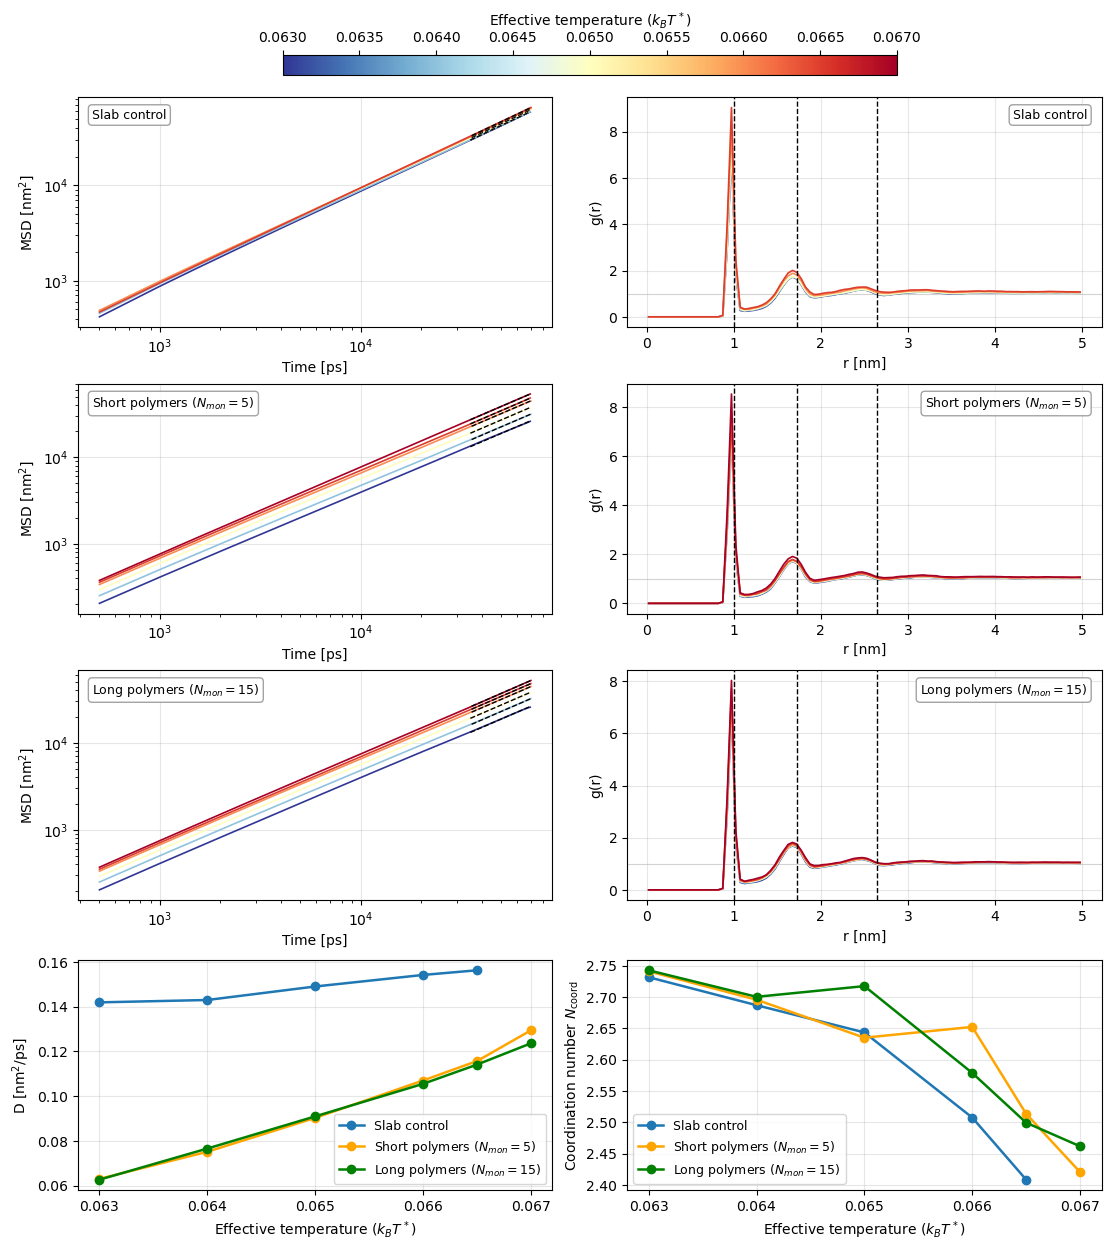

In [32]:
FOLDERS = ["Slab/Control", "Slab/Reg_pol_5/Phase_sep", "Slab/Reg_pol_15"]
LABELS  = ["Slab control", r"Short polymers $(N_{mon}=5)$", r"Long polymers $(N_{mon}=15)$"]
COLORS = ["#1f77b4", "orange", "green"]

fig, axes, results = plot_msd_rdf_comparison(
    folders=FOLDERS,                           # the n main folders
    labels=LABELS,
    folder_colors=COLORS,                      # last-row curves
    cmap="RdYlBu_r",                           # any matplotlib name, or a Colormap
    msd_tail_fraction=0.5,
    last_xticks=[0.063, 0.064, 0.065, 0.066, 0.067],
    savepath="msd_rdf_comparison_slab.png",
)

### FULL BOX control, LJ_0.05

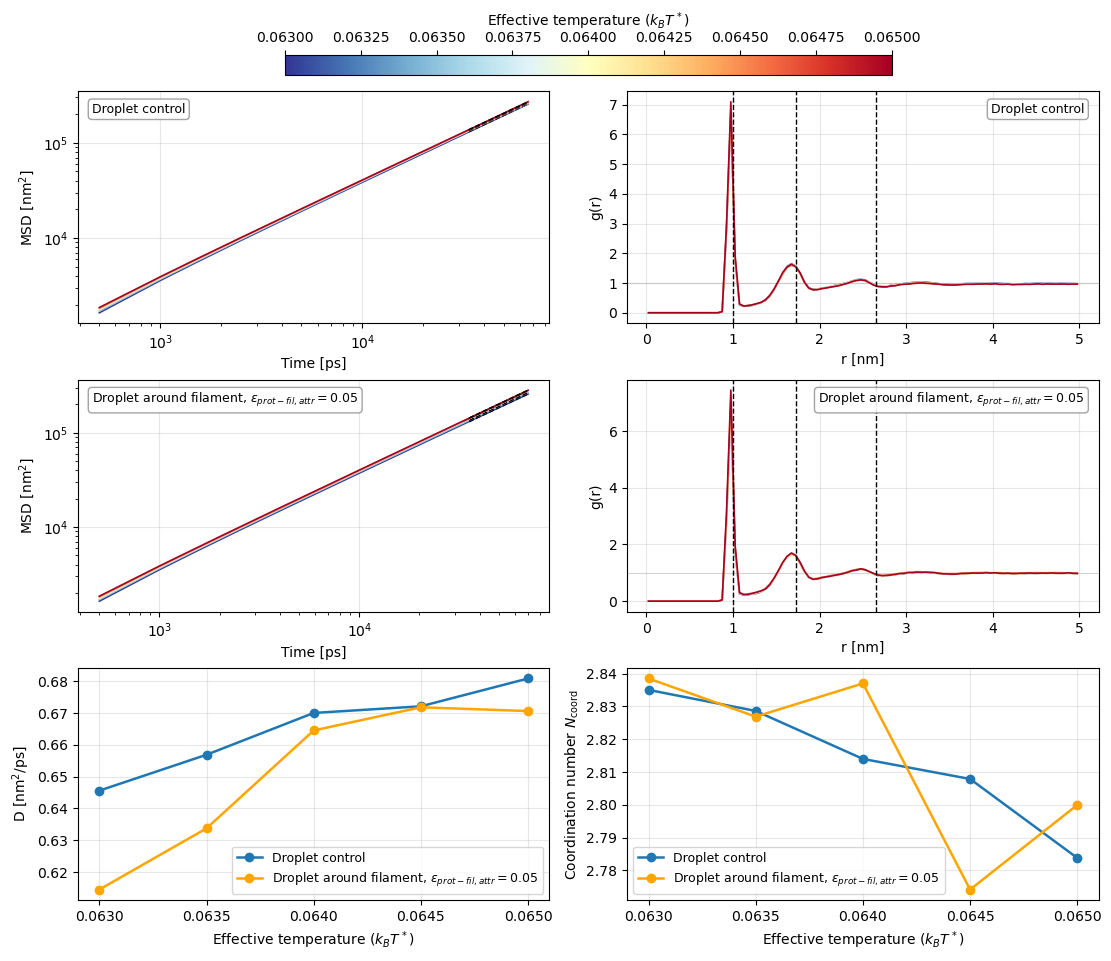

In [91]:
FOLDERS = ["Full_box/MSD_and_RDF/Control", "Full_box/MSD_and_RDF/LJ_0.05"]
LABELS  = ["Droplet control", r"Droplet around filament, $\epsilon_{prot-fil, attr}=0.05$"]
COLORS = ["#1f77b4", "orange"]

fig, axes, results = plot_msd_rdf_comparison(
    folders=FOLDERS,                           # the n main folders
    labels=LABELS,
    folder_colors=COLORS,                      # last-row curves
    cmap="RdYlBu_r",                           # any matplotlib name, or a Colormap
    msd_tail_fraction=0.5,
    last_xticks=[0.0630, 0.0635, 0.0640, 0.0645, 0.0650],
    savepath="msd_rdf_comparison_full_box.png",
)

### FULL BOX DIFFUSION LJ_0.05

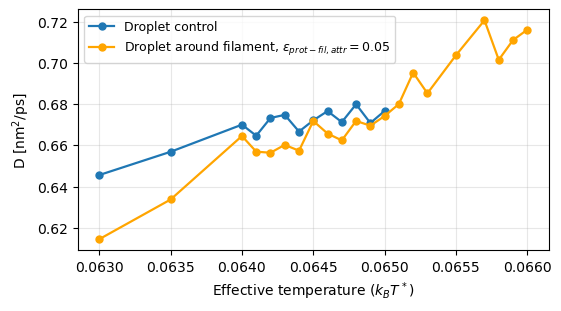

In [10]:
FOLDERS = ["Full_box/Control", "Full_box/LJ_force/LJ_0.05"]
LABELS  = ["Droplet control", r"Droplet around filament, $\epsilon_{prot-fil, attr}=0.05$"]
COLORS = ["#1f77b4", "orange"]

fig, ax, D = plot_diffusion_vs_temperature(
    FOLDERS,
    labels=LABELS,
    folder_colors=COLORS,
    msd_tail_fraction=0.5,
    last_xticks=None,
    max_temp=0.068,
    log_D=False,
    figsize=(5.5, 3.0),
    savepath="D_vs_T_fullbox.png",
)

### Sim geometry effects: the 2 controls

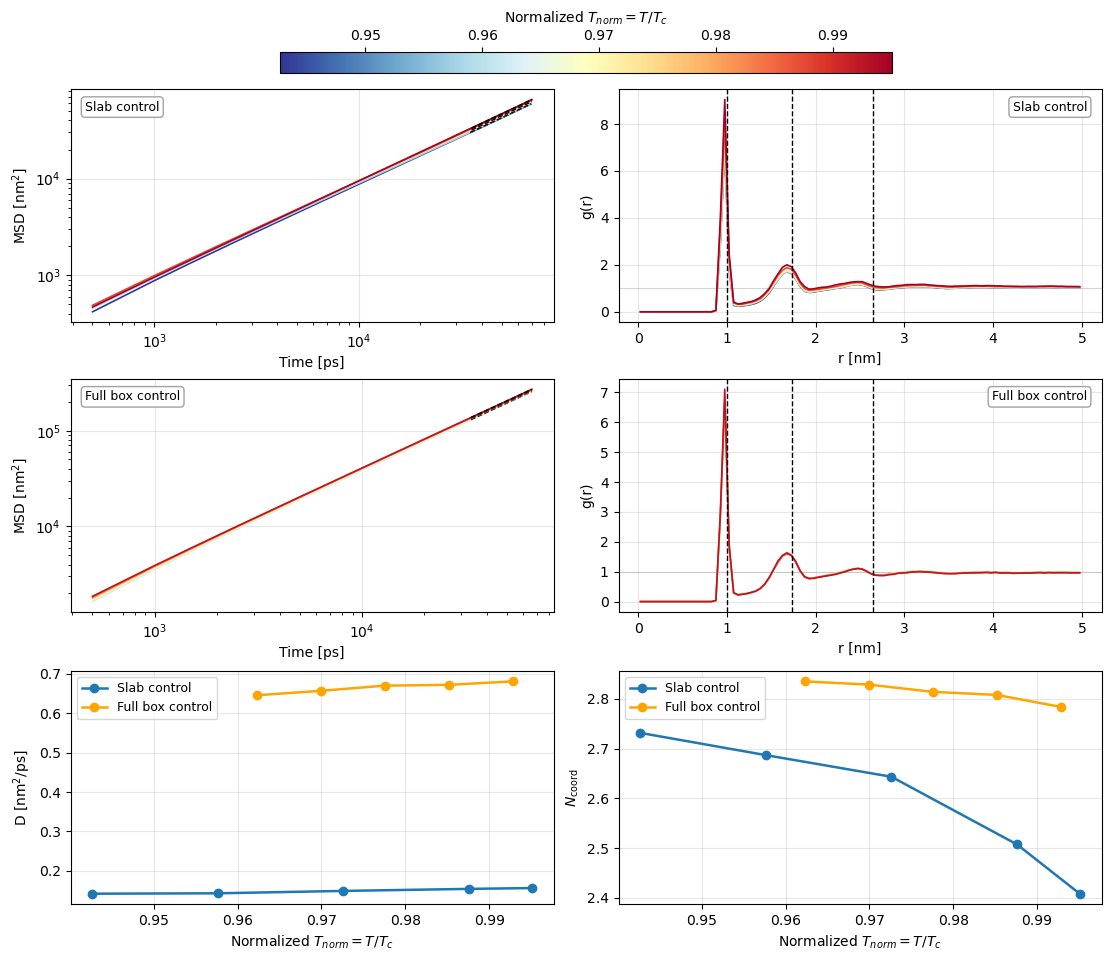

In [26]:
FOLDERS = ["Slab/Control", "Full_box/MSD_and_RDF/Control"]
LABELS  = ["Slab control", "Full box control"]
COLORS = ["#1f77b4", "orange"]
CRIT_TEMPS = [0.066828872536696, 0.06547048550893132]

# Critical temperatures from phase diagrams:
# 0.066828872536696    (slab)
# 0.06547048550893132 (full_box)

fig, axes, results = plot_msd_rdf_comparison(
    folders=FOLDERS,                           # the n main folders
    labels=LABELS,
    folder_colors=COLORS,                      # last-row curves
    cmap="RdYlBu_r",                           # any matplotlib name, or a Colormap, e.g. plasma
    crit_temps=CRIT_TEMPS,
    msd_tail_fraction=0.5,
    last_xticks=None,                           # [0.0630, 0.0635, 0.0640, 0.0645, 0.0650],
    savepath="msd_rdf_sim_geom_effects.png",
)

## Potentials comparison

In [16]:
def mie_prefactor(n, m):
    """C(n, m) of the Mie potential; equals 4 for (12, 6) and for (2, 1)."""
    n, m = float(n), float(m)
    return (n / (n - m)) * (n / m) ** (m / (n - m))


def expanded_mie(r, epsilon, sigma, delta, n=2.0, m=1.0):
    """
    U(r) = C(n,m) * eps * [ (sigma/(r-delta))**n - (sigma/(r-delta))**m ]

    The simulation uses n=2, m=1, where C = 4, so this reduces to the form
    written on the slide.  Values at r <= delta are undefined and come back as
    NaN, which matplotlib simply leaves blank.
    """
    r = np.asarray(r, dtype=float)
    shifted = r - float(delta)
    eps_shift = 2/9 * mie_prefactor(n, m) * float(epsilon)
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio = float(sigma) / shifted
        return mie_prefactor(n, m) * float(epsilon) * (ratio ** n - ratio ** m) + eps_shift


def lennard_jones(r, epsilon, sigma, r_cut=None, shift=False):
    """
    U(r) = 4 eps [ (sigma/r)**12 - (sigma/r)**6 ], zero beyond r_cut.

    shift=False matches HOOMD's default mode="none", which your simulation
    uses: the potential is simply truncated, so it jumps to zero at r_cut.
    shift=True subtracts U(r_cut), HOOMD's mode="shift", which makes the
    purely repulsive (WCA) form go smoothly to zero.
    """
    r = np.asarray(r, dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio = np.where(r > 0, float(sigma) / r, np.nan)
        u = 4.0 * float(epsilon) * (ratio ** 12 - ratio ** 6)
    if r_cut is not None:
        if shift:
            rc = float(sigma) / float(r_cut)
            u = u - 4.0 * float(epsilon) * (rc ** 12 - rc ** 6)
        u = np.where(r <= float(r_cut), u, 0.0)
    return u


def _label(name, params):
    epsilon_val = params["epsilon"]
    return name + ": " + rf"$\epsilon = ${epsilon_val}"
    # return name + "  " + ", ".join(
    #     f"{k}={v:.4g}" if isinstance(v, (int, float)) and not isinstance(v, bool) else f"{k}={v}"
    #     for k, v in params.items()
    # )


def plot_potentials(
    mie_params=dict(epsilon=1.0, sigma=1.0, delta=0.0, n=2, m=1),
    mie_r_cut=2.0,
    lj_params=dict(epsilon=1.0, sigma=1.0, r_cut=2.0 ** (1.0 / 6.0)),
    lj2_params=None,
    mie_r=None,
    lj_r=None,
    lj2_r=None,
    xlim=None,
    ylim=None,
    mie_ylim=None,
    figsize=(7.0, 7.0),
    mie_color="violet",
    lj_color="red",
    lj2_color="blue",
    lj_names=("LJ repulsive", "LJ attractive"),
    mark_minimum=True,
    mark_cutoff=True,
):
    """
    Expanded Mie (top, green) and one or two Lennard-Jones potentials (bottom).

    mie_r, lj_r, lj2_r are the r arrays each curve is evaluated on, so every
    curve can start and stop where you want.  lj_params / lj2_params take
    epsilon, sigma and optionally r_cut and shift (see lennard_jones); the
    curve is zero beyond its r_cut, and mark_cutoff draws a dotted line there.
    lj2_params=None plots only the first LJ.

    Both panels share one x axis; xlim sets it, otherwise it spans all arrays.
    ylim applies to the LJ panel, mie_ylim to the Mie panel (default: ylim).
    Returns (fig, axes).
    """
    if mie_r is None:
        mie_r = np.linspace(0.8, 5.0, 2000)
    if lj_r is None:
        lj_r = np.linspace(0.8, 3.0, 2000)
    if lj2_params is not None and lj2_r is None:
        lj2_r = np.linspace(0.8, 3.0, 2000)

    fig, axes = plt.subplots(2, 1, figsize=figsize, sharex=False)

    # --- top: expanded Mie ----------------------------------------------------
    u_mie = expanded_mie(mie_r, **mie_params)
    axes[0].plot(mie_r, u_mie, color=mie_color, lw=2.0,
                 label=_label("Expanded Mie", mie_params))
    axes[0].axvline(float(mie_r_cut), color=mie_color, lw=1.5, ls="--", alpha=0.8)
    axes[0].set_xlabel("r [nm]")

    # --- bottom: one or two LJ curves -----------------------------------------
    lj_curves = [(lj_r, lj_params, lj_color, lj_names[0])]
    if lj2_params is not None:
        lj_curves.append((lj2_r, lj2_params, lj2_color, lj_names[1]))

    for r, params, color, name in lj_curves:
        r = np.asarray(r, dtype=float)
        u = lennard_jones(r, **params)
        axes[1].plot(r, u, color=color, lw=2.0, label=_label(name, params))
        if mark_cutoff and params.get("r_cut") is not None:
            axes[1].axvline(float(params["r_cut"]), color=color, lw=1.5, ls="--", alpha=0.8)

    # --- shared styling ---------------------------------------------------------
    all_r = [np.asarray(mie_r, dtype=float)] + [np.asarray(c[0], dtype=float) for c in lj_curves]
    panel_limits = ((axes[0], mie_ylim if mie_ylim is not None else ylim), (axes[1], ylim))
    for ax, panel_ylim in panel_limits:
        ax.axhline(0.0, color="grey", lw=1.5, ls=":")
        if mark_minimum:
            for line in list(ax.get_lines()):
                x, y = np.asarray(line.get_xdata()), np.asarray(line.get_ydata())
                if len(x) < 3 or not np.any(np.isfinite(y)):
                    continue
                i = int(np.nanargmin(y))
                if y[i] < 0:
                    ax.plot(x[i], y[i], marker="o", color=line.get_color(), markersize=5)
                    ax.annotate(f"({x[i]:.3g}, {y[i]:.3g})", (x[i], y[i]),
                                textcoords="offset points", xytext=(8, -8), fontsize=8)
        ax.set_ylabel("U(r) [kJ/mol]")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, loc="upper right")
        if panel_ylim is not None:
            ax.set_ylim(*panel_ylim)

    axes[-1].set_xlabel("r [nm]")
    if xlim is None:
        xlim = (min(a.min() for a in all_r), max(a.max() for a in all_r))
    axes[-1].set_xlim(*xlim)
    fig.tight_layout()
    return fig, axes

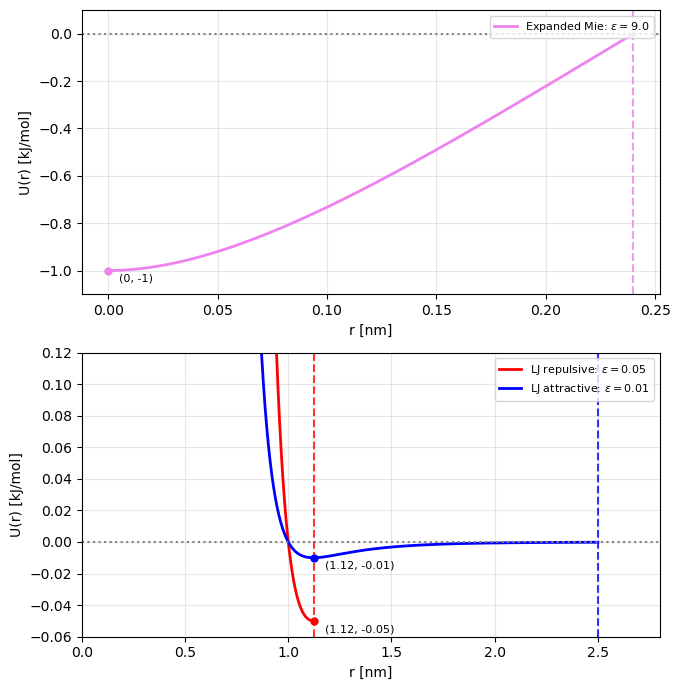

In [17]:
sigma_core = 1.0
fig, axes = plot_potentials(
    mie_params=dict(epsilon=9.0, sigma=2*0.12, delta=-4*0.12, n=2, m=1),
    mie_r_cut=2*0.12,
    lj_params=dict(epsilon=0.05, sigma=sigma_core, r_cut=2 ** (1 / 6) * sigma_core),   # red, repulsive
    lj2_params=dict(epsilon=0.01, sigma=sigma_core, r_cut=2.5 * sigma_core),           # blue, attractive
    mie_r=np.linspace(0.0, 2*0.12, 2000),
    lj_r=np.linspace(0.9, 2 ** (1 / 6) * sigma_core, 400),
    lj2_r=np.linspace(0.7, 2.5 * sigma_core, 1500),
    xlim=(0.0, 2.8),
    ylim=(-0.06, 0.12),       # LJ panel
    mie_ylim=(-1.1, 0.1),       # Mie panel; defaults to ylim if left out
)
fig.savefig("General_interact_potentials.png", dpi=300, bbox_inches="tight")

In [21]:
from fractions import Fraction
from matplotlib.ticker import MultipleLocator, FuncFormatter


def _pi_tick_label(x, pos=None, max_denominator=24):
    """Format a radian value as a fraction of pi."""
    frac = Fraction(x / np.pi).limit_denominator(max_denominator)
    n, d = frac.numerator, frac.denominator

    if n == 0:
        return "0"

    sign = "-" if n < 0 else ""
    n = abs(n)
    num = r"\pi" if n == 1 else rf"{n}\pi"

    if d == 1:
        return rf"${sign}{num}$"
    return rf"${sign}\frac{{{num}}}{{{d}}}$"


def set_pi_ticks(ax, step=np.pi / 12, minor=None, axis="x"):
    """Label `axis` of `ax` in multiples of pi, spaced by `step`."""
    target = ax.xaxis if axis == "x" else ax.yaxis
    target.set_major_locator(MultipleLocator(step))
    target.set_major_formatter(FuncFormatter(_pi_tick_label))
    if minor is not None:
        target.set_minor_locator(MultipleLocator(minor))
    return ax

    
def bond_potential(r, k_b=1000.0, r0=0.465):
    """Harmonic bond potential: 0.5 * k_b * (r - r0)^2."""
    return 0.5 * k_b * (np.asarray(r) - r0) ** 2


def angle_potential(theta, k_a=10.0, theta0=120.0):
    """Harmonic angle potential: 0.5 * k_a * (theta - theta0)^2, theta in degrees. Now converted to radians"""
    return 0.5 * k_a * (np.asarray(theta) * np.pi/180.0 - theta0 * np.pi/180.0) ** 2


def plot_harmonic_potentials(r_range=(0.365, 0.565),
                             theta_range=(90.0, 150.0),
                             k_b=1000.0, r0=0.465,
                             k_a=10.0, theta0=120.0,
                             n=400):
    """Plot the bond and angle potentials side by side."""
    r = np.linspace(*r_range, n)
    theta = np.linspace(*theta_range, n)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    axes[0].plot(r, bond_potential(r, k_b, r0), color="tab:blue")
    axes[0].axvline(r0, ls="--", lw=0.8, color="gray")
    axes[0].set_xlabel(r"$r$ [$\sigma$]")
    axes[0].set_ylabel(r"$U_\mathrm{bond}$ [$energy \ unit$]")
    axes[0].set_title(rf"$k_b(r-r_0)^2$,  $k_b={k_b:g}$,  $r_0={r0:g}$")

    axes[1].plot(theta * np.pi/180.0, angle_potential(theta, k_a, theta0), color="tab:red")
    axes[1].axvline(theta0 * np.pi/180.0, ls="--", lw=0.8, color="gray")
    set_pi_ticks(axes[1], step=np.pi / 12)
    axes[1].set_xlabel(r"$\theta$ [$rad$]")
    axes[1].set_ylabel(r"$U_\mathrm{angle}$ [$energy \ unit$]")
    axes[1].set_title(rf"$k_a(\theta-\theta_0)^2$,  $k_a={k_a:g}$,  $\theta_0={theta0:g}^\circ$")

    for ax in axes:
        ax.grid(alpha=0.3)

    fig.tight_layout()
    return fig, axes

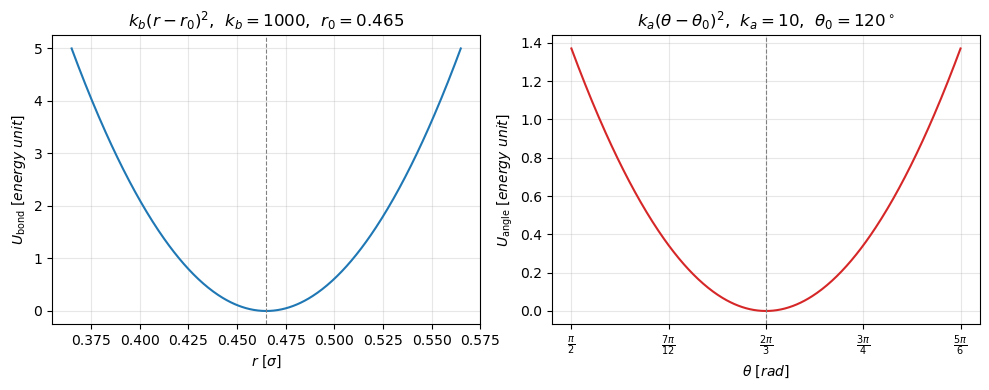

In [22]:
fig, axes = plot_harmonic_potentials()
plt.show()
fig.savefig("Flexible_patchy_potentials.png", dpi=300, bbox_inches="tight")